# Stories Coffee: a playbook for abrupt change

**Business problem:** How can Stories apply changes to maximize profit in times of abrupt change?

The final three-part argument is about **demand and preparation**, **observational promotion results**, and **customer continuity with testable intervention timing**. Supporting food-offer and branch-cost investigations remain in section 6.

Dates supplied by the team: March 2 war-context cutoff; Ramadan February 17–March 18; Lent February 18–April 2, inclusive. Overlap and concurrent changes prevent clean causal attribution. Recorded gross profit excludes unrecorded operating costs.

Run all locally after installing requirements, or upload this notebook to Colab and upload the supplied CSV. The package sources and promotion script are embedded for standalone execution.

In [1]:
from pathlib import Path
import sys, os, tempfile
import pandas as pd
from IPython.display import display, Image

# Colab may not ship the calendar model dependency. Install only if absent.
import importlib.util
if importlib.util.find_spec('statsmodels') is None:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'statsmodels>=0.14,<0.15'])

# Use repository sources locally; embedded copies make this file portable to Colab.
PROJECT = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / 'src/stories/analysis.py').exists()), None)
if PROJECT is None:
    PROJECT = Path(tempfile.mkdtemp(prefix='stories-coffee-'))
    package = PROJECT / 'src/stories'
    package.mkdir(parents=True)
    embedded_sources = {'__init__.py': '"""Reproducible Stories Coffee decision analysis."""\n', 'scenario.py': '"""Conditional economics; conversion inputs are assumptions, never predictions."""\nimport argparse\nimport json\n\n\ndef evaluate(*, eligible_orders, additional_attachment, food_price, food_cost,\n             discount=0.0, baseline_attachment=0.0, substitution_rate=0.0,\n             displaced_contribution=0.0, waste_units=0.0, extra_cost_per_addition=0.0,\n             fixed_cost=0.0):\n    """Rates use eligible orders as denominator; baseline and additional are disjoint.\n\n    baseline_attachment represents purchases that would occur without the offer but\n    receive its discount. Substitution is a fraction of additional purchases.\n    Waste is additional unsold units, charged at recorded unit cost.\n    """\n    values = locals().copy()\n    if any(v < 0 for v in values.values()):\n        raise ValueError(\'Inputs must be nonnegative.\')\n    if eligible_orders <= 0:\n        raise ValueError(\'eligible_orders must be positive.\')\n    if any(r > 1 for r in (additional_attachment, baseline_attachment, substitution_rate)):\n        raise ValueError(\'Rates must lie between zero and one.\')\n    if additional_attachment + baseline_attachment > 1:\n        raise ValueError(\'Baseline plus additional attachment cannot exceed one.\')\n    if discount > food_price:\n        raise ValueError(\'Discount cannot exceed food price.\')\n    contribution = (food_price - food_cost - discount - extra_cost_per_addition\n                    - substitution_rate * displaced_contribution)\n    leakage = eligible_orders * baseline_attachment * discount\n    overhead = waste_units * food_cost + fixed_cost\n    profit = eligible_orders * additional_attachment * contribution - leakage - overhead\n    threshold = ((leakage + overhead) / (eligible_orders * contribution)\n                 if contribution > 0 else None)\n    return {\n        \'inputs\': values,\n        \'net_contribution_per_addition_usd\': contribution,\n        \'additional_purchases\': eligible_orders * additional_attachment,\n        \'discount_leakage_usd\': leakage,\n        \'incremental_gross_profit_after_assumed_costs_usd\': profit,\n        \'incremental_profit_per_eligible_order_usd\': profit / eligible_orders,\n        \'break_even_additional_attachment\': threshold,\n        \'break_even_feasible\': threshold is not None and threshold <= 1 - baseline_attachment,\n        \'interpretation\': \'Conditional scenario, not measured uplift or net company profit.\',\n    }\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    for name, default in [(\'eligible-orders\', 1000), (\'additional-attachment\', .05),\n                          (\'food-price\', None), (\'food-cost\', None), (\'discount\', 0.),\n                          (\'baseline-attachment\', 0.), (\'substitution-rate\', 0.),\n                          (\'displaced-contribution\', 0.), (\'waste-units\', 0.),\n                          (\'extra-cost-per-addition\', 0.), (\'fixed-cost\', 0.)]:\n        p.add_argument(\'--\' + name, type=float, default=default, required=default is None)\n    print(json.dumps(evaluate(**vars(p.parse_args())), indent=2, allow_nan=False))\n\n\nif __name__ == \'__main__\':\n    main()\n', 'calendar.py': '"""Retrospective calendar comparisons, never causal attribution or real-time forecasts."""\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\nimport statsmodels.api as sm\n\nRAMADAN_START = pd.Timestamp(\'2026-02-17\')\nRAMADAN_END = pd.Timestamp(\'2026-03-18\')\nLENT_START = pd.Timestamp(\'2026-02-18\')\nLENT_END = pd.Timestamp(\'2026-04-02\')\nCHANGE_DATE = pd.Timestamp(\'2026-03-02\')\nPHASES = [\'Before both / before March 2\', \'Ramadan only: one day\',\n          \'Ramadan + Lent / before March 2\', \'Ramadan + Lent / after March 2\',\n          \'Lent only / after March 2\', \'After both / after March 2\']\n\n\ndef annotate(frame):\n    x = frame.copy()\n    x[\'ramadan\'] = x.date.between(RAMADAN_START, RAMADAN_END).astype(int)\n    x[\'lent\'] = x.date.between(LENT_START, LENT_END).astype(int)\n    x[\'post_march2\'] = (x.date >= CHANGE_DATE).astype(int)\n    conditions = [x.date < RAMADAN_START, x.date < LENT_START,\n                  x.date < CHANGE_DATE, x.date <= RAMADAN_END, x.date <= LENT_END]\n    x[\'phase\'] = np.select(conditions, PHASES[:-1], default=PHASES[-1])\n    return x\n\n\ndef daily_metrics(d, b):\n    rows = []\n    for branch in [\'All branches\', *sorted(d.branch.unique())]:\n        items = d if branch == \'All branches\' else d[d.branch == branch]\n        orders = b if branch == \'All branches\' else b[b.branch == branch]\n        orders = orders.assign(evening=orders.hour >= 18,\n            midday=orders.hour.between(11, 15),\n            takeaway=orders.order_type.eq(\'Takeaway\'),\n            breakfast=orders.index.isin(items.loc[items.category == \'Breakfast\', \'transaction\']),\n            drink_bakery=orders.drink & orders.bakery,\n            drink_meal=orders.drink & orders.meal)\n        s = orders.groupby(\'date\').agg(orders=(\'branch\', \'size\'),\n            gross_profit=(\'gross_profit\', \'sum\'), revenue=(\'revenue\', \'sum\'),\n            evening_orders=(\'evening\', \'sum\'), midday_orders=(\'midday\', \'sum\'),\n            takeaway_orders=(\'takeaway\', \'sum\'), breakfast_orders=(\'breakfast\', \'sum\'),\n            drink_orders=(\'drink\', \'sum\'), bakery_drink_orders=(\'drink_bakery\', \'sum\'),\n            meal_drink_orders=(\'drink_meal\', \'sum\'), eligible_orders=(\'eligible\', \'sum\'))\n        dates = pd.date_range(d.date.min(), d.date.max())\n        s = s.reindex(dates, fill_value=0)\n        unit = items.assign(discounted_units=items.quantity * items.discount.gt(0)).groupby(\'date\').agg(\n            units=(\'quantity\', \'sum\'), discounted_units=(\'discounted_units\', \'sum\'))\n        s = s.join(unit).fillna(0)\n        s[\'branch\'] = branch\n        s.index.name = \'date\'; s = s.reset_index()\n        rows.append(s)\n    daily = annotate(pd.concat(rows, ignore_index=True))\n    return add_rates(daily)\n\n\ndef add_rates(s):\n    s = s.copy()\n    denominator = s.orders.replace(0, np.nan)\n    for metric in [\'evening\', \'midday\', \'takeaway\', \'breakfast\']:\n        s[f\'{metric}_share\'] = s[f\'{metric}_orders\'] / denominator\n    s[\'gross_profit_per_order\'] = s.gross_profit / denominator\n    s[\'bakery_attachment\'] = s.bakery_drink_orders / s.drink_orders.replace(0, np.nan)\n    s[\'meal_attachment\'] = s.meal_drink_orders / s.drink_orders.replace(0, np.nan)\n    s[\'discounted_unit_share\'] = s.discounted_units / s.units.replace(0, np.nan)\n    return s\n\n\ndef phase_summary(daily):\n    counts = [\'orders\', \'gross_profit\', \'revenue\', \'evening_orders\', \'midday_orders\',\n              \'takeaway_orders\', \'breakfast_orders\', \'drink_orders\', \'bakery_drink_orders\',\n              \'meal_drink_orders\', \'eligible_orders\', \'units\', \'discounted_units\']\n    s = daily.groupby([\'branch\', \'phase\'])[counts].sum()\n    s[\'days\'] = daily.groupby([\'branch\', \'phase\']).date.nunique()\n    s = add_rates(s.reset_index())\n    s[\'orders_per_day\'] = s.orders / s.days\n    s[\'eligible_orders_per_day\'] = s.eligible_orders / s.days\n    order = {p: i for i, p in enumerate(PHASES)}\n    return s.assign(_sort=s.phase.map(order)).sort_values([\'branch\', \'_sort\']).drop(columns=\'_sort\')\n\n\ndef category_phases(d, daily):\n    rows = []\n    exposure = daily.set_index([\'branch\', \'phase\']).groupby(level=[0, 1]).size()\n    for branch in [\'All branches\', *sorted(d.branch.unique())]:\n        x = annotate(d if branch == \'All branches\' else d[d.branch == branch])\n        s = x.assign(discounted_units=x.quantity * x.discount.gt(0)).groupby([\'phase\', \'category\']).agg(\n            units=(\'quantity\', \'sum\'), gross_profit=(\'gross_profit\', \'sum\'),\n            discounted_units=(\'discounted_units\', \'sum\')).reset_index()\n        s[\'branch\'] = branch\n        s[\'phase_days\'] = s.phase.map(exposure.loc[branch])\n        s[\'units_per_day\'] = s.units / s.phase_days\n        s[\'unit_share\'] = s.units / s.groupby(\'phase\').units.transform(\'sum\')\n        s[\'gross_profit_per_unit\'] = s.gross_profit / s.units\n        s[\'discounted_unit_share\'] = s.discounted_units / s.units\n        rows.append(s)\n    return pd.concat(rows, ignore_index=True)\n\n\ndef boundary_comparisons(daily):\n    events = [(\'Joint calendar start\', RAMADAN_START), (\'March 2\', CHANGE_DATE),\n              (\'Ramadan ended\', RAMADAN_END + pd.Timedelta(days=1)),\n              (\'Lent ended\', LENT_END + pd.Timedelta(days=1))]\n    rows = []\n    for branch, g in daily.groupby(\'branch\'):\n        for event, date in events:\n            for width in [7, 14]:\n                pre = g[(g.date >= date - pd.Timedelta(days=width)) & (g.date < date)]\n                post = g[(g.date >= date) & (g.date < date + pd.Timedelta(days=width))]\n                if len(pre) != width or len(post) != width:\n                    continue\n                total = add_rates(pd.DataFrame([pre.sum(numeric_only=True), post.sum(numeric_only=True)]))\n                for metric in [\'orders\', \'evening_share\', \'midday_share\', \'gross_profit_per_order\',\n                               \'bakery_attachment\', \'meal_attachment\', \'discounted_unit_share\']:\n                    before, after = total[metric].tolist()\n                    change = ((after / before - 1) * 100 if metric == \'orders\'\n                              else (after - before) * (1 if metric == \'gross_profit_per_order\' else 100))\n                    rows.append(dict(branch=branch, event=event, boundary_date=date,\n                        window_days_each_side=width, metric=metric, before=before, after=after,\n                        change=change, change_unit=\'percent\' if metric == \'orders\' else\n                        (\'USD/order\' if metric == \'gross_profit_per_order\' else \'percentage points\'),\n                        pre_ramadan_days=int(pre.ramadan.sum()), post_ramadan_days=int(post.ramadan.sum()),\n                        pre_lent_days=int(pre.lent.sum()), post_lent_days=int(post.lent.sum()),\n                        pre_postmarch2_days=int(pre.post_march2.sum()), post_postmarch2_days=int(post.post_march2.sum())))\n    return pd.DataFrame(rows)\n\n\ndef model_associations(daily):\n    """OLS with weekday/trend adjustment and HAC errors; full-sample associations only."""\n    records, diagnostics = [], []\n    specs = [(\'through_April_linear\', \'2026-04-30\', False, False),\n             (\'through_April_quadratic\', \'2026-04-30\', True, False),\n             (\'through_June_linear\', \'2026-06-30\', False, False),\n             (\'through_June_quadratic\', \'2026-06-30\', True, False),\n             (\'through_June_post_slope\', \'2026-06-30\', False, True)]\n    metrics = [\'orders\', \'evening_share\', \'midday_share\', \'gross_profit_per_order\',\n               \'bakery_attachment\', \'meal_attachment\', \'breakfast_share\', \'discounted_unit_share\']\n    for branch, g in daily.groupby(\'branch\'):\n        for spec, end, quadratic, post_slope in specs:\n            z = g[g.date <= end].sort_values(\'date\').copy()\n            t = (z.date - daily.date.min()).dt.days / 7\n            X = pd.DataFrame({\'intercept\': 1., \'trend_weeks\': t,\n                              \'ramadan\': z.ramadan, \'lent\': z.lent,\n                              \'post_march2\': z.post_march2}, index=z.index)\n            if quadratic:\n                X[\'trend_squared\'] = t ** 2\n            if post_slope:\n                X[\'post_trend_weeks\'] = ((z.date - CHANGE_DATE).dt.days / 7).clip(lower=0)\n            for day in range(1, 7):\n                X[f\'weekday_{day}\'] = z.date.dt.dayofweek.eq(day).astype(float)\n            for metric in metrics:\n                mask = z[metric].notna() & (z[metric].gt(0) if metric == \'orders\' else True)\n                target = np.log(z.loc[mask, metric]) if metric == \'orders\' else z.loc[mask, metric]\n                fit = sm.OLS(target, X.loc[mask].astype(float)).fit(cov_type=\'HAC\',\n                    cov_kwds={\'maxlags\': 7, \'use_correction\': True}, use_t=True)\n                intervals = fit.conf_int()\n                for term in [\'ramadan\', \'lent\', \'post_march2\']:\n                    scale = (lambda v: 100 * np.expm1(v)) if metric == \'orders\' else (\n                        (lambda v: v) if metric == \'gross_profit_per_order\' else (lambda v: 100 * v))\n                    records.append(dict(branch=branch, specification=spec, metric=metric,\n                        term=term, association=scale(fit.params[term]),\n                        ci_lower=scale(intervals.loc[term, 0]), ci_upper=scale(intervals.loc[term, 1]),\n                        unit=\'percent\' if metric == \'orders\' else (\'USD/order\' if metric == \'gross_profit_per_order\' else \'percentage points\'),\n                        n_days=int(fit.nobs), causal=False))\n            diagnostics.append(dict(branch=branch, specification=spec, n_days=len(z),\n                design_rank=int(np.linalg.matrix_rank(X)), design_columns=len(X.columns),\n                condition_number=float(np.linalg.cond(X)),\n                ramadan_lent_correlation=float(z.ramadan.corr(z.lent))))\n    return pd.DataFrame(records), pd.DataFrame(diagnostics)\n\n\ndef calendar_figures(daily, associations, output):\n    import matplotlib.pyplot as plt\n    x = daily[daily.branch == \'All branches\'].set_index(\'date\')\n    fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)\n    for ax, metric, title, multiplier in zip(axes,\n        [\'orders\', \'evening_share\', \'gross_profit_per_order\'],\n        [\'Orders/day (7-day mean)\', \'Evening orders, 18:00–23:59 (%)\', \'Gross profit/order (USD)\'],\n        [1, 100, 1]):\n        ax.plot(x.index, x[metric].rolling(7, min_periods=7).mean() * multiplier, color=\'#334155\')\n        ax.axvspan(RAMADAN_START, RAMADAN_END + pd.Timedelta(days=1), color=\'#0d9488\', alpha=.15, label=\'Ramadan (supplied dates)\')\n        ax.axvspan(LENT_START, LENT_END + pd.Timedelta(days=1), color=\'#b283df\', alpha=.13, label=\'Lent (supplied dates)\')\n        ax.axvline(CHANGE_DATE, color=\'#c25a28\', ls=\'--\', label=\'March 2 cutoff\')\n        ax.set_ylabel(title)\n    axes[0].legend(loc=\'upper left\', fontsize=8)\n    fig.suptitle(\'Calendar overlap and observed trading patterns — no causal attribution\')\n    fig.tight_layout(); fig.savefig(output / \'calendar_timeline.png\', dpi=150); plt.close(fig)\n    a = associations[(associations.branch == \'All branches\') &\n                     (associations.metric == \'orders\')]\n    fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)\n    specs = a.specification.unique()\n    for ax, term in zip(axes, [\'ramadan\', \'lent\', \'post_march2\']):\n        s = a[a.term == term].set_index(\'specification\').loc[specs]\n        y = np.arange(len(s))\n        ax.errorbar(s.association, y,\n            xerr=np.vstack([s.association - s.ci_lower, s.ci_upper - s.association]),\n            fmt=\'o\', capsize=3, color=\'#0d7e77\')\n        ax.axvline(0, color=\'#64748b\', ls=\'--\'); ax.set_title(term)\n        ax.set_xlabel(\'Adjusted association with daily orders (%)\')\n        ax.set_yticks(y, specs)\n    fig.suptitle(\'Retrospective model sensitivity; 95% HAC intervals are conditional on each model\')\n    fig.tight_layout(); fig.savefig(output / \'calendar_model_sensitivity.png\', dpi=150); plt.close(fig)\n\n\ndef run_calendar(d, b, output):\n    output = Path(output)\n    daily = daily_metrics(d, b)\n    phases = phase_summary(daily)\n    categories = category_phases(d, daily)\n    boundaries = boundary_comparisons(daily)\n    associations, diagnostics = model_associations(daily)\n    for name, table in [(\'calendar_daily_metrics\', daily), (\'calendar_phase_summary\', phases),\n                        (\'calendar_category_phases\', categories), (\'calendar_boundary_comparisons\', boundaries),\n                        (\'calendar_adjusted_associations\', associations),\n                        (\'calendar_model_diagnostics\', diagnostics)]:\n        table.to_csv(output / f\'{name}.csv\', index=False)\n    calendar_figures(daily, associations, output / \'figures\')\n    return {\'daily\': daily, \'phases\': phases, \'categories\': categories, \'boundaries\': boundaries,\n            \'associations\': associations, \'diagnostics\': diagnostics}\n', 'diagnostics.py': '"""Selected diagnostics adapted from the two supplied exploratory notebooks."""\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\n\nfrom .calendar import RAMADAN_START, RAMADAN_END, LENT_START, LENT_END, CHANGE_DATE\n\n\ndef calendar_exposure(start, end):\n    dates = pd.date_range(start, end)\n    return {\'ramadan_days\': int(((dates >= RAMADAN_START) & (dates <= RAMADAN_END)).sum()),\n            \'lent_days\': int(((dates >= LENT_START) & (dates <= LENT_END)).sum())}\n\n\ndef category_windows(d, cutoff=CHANGE_DATE, widths=(14, 28, 42)):\n    summaries, exposure = [], []\n    for width in widths:\n        start, end = cutoff-pd.Timedelta(days=width), cutoff+pd.Timedelta(days=width-1)\n        if start < d.date.min() or end > d.date.max():\n            continue\n        for period, left, right in [(\'Before\', start, cutoff-pd.Timedelta(days=1)),\n                                    (\'After\', cutoff, end)]:\n            exposure.append(dict(days_each_side=width, period=period, start=left, end=right,\n                                 **calendar_exposure(left, right)))\n            x = d[d.date.between(left, right)].copy()\n            x[\'discounted_units\'] = x.quantity * x.discount.gt(0)\n            for branch in [\'All branches\', *sorted(d.branch.unique())]:\n                items = x if branch == \'All branches\' else x[x.branch == branch]\n                s = items.groupby(\'category\').agg(units=(\'quantity\', \'sum\'),\n                    revenue=(\'revenue\', \'sum\'), gross_profit=(\'gross_profit\', \'sum\'),\n                    discounted_units=(\'discounted_units\', \'sum\')).reset_index()\n                s[\'units_per_day\'] = s.units / width\n                s[\'gross_profit_per_day\'] = s.gross_profit / width\n                s[\'gross_profit_per_unit\'] = s.gross_profit / s.units\n                s[\'unit_share\'] = s.units / s.units.sum()\n                s[\'discounted_unit_share\'] = s.discounted_units / s.units\n                s[\'branch\'], s[\'period\'], s[\'days_each_side\'] = branch, period, width\n                summaries.append(s)\n    s = pd.concat(summaries, ignore_index=True)\n    keys = [\'branch\', \'category\', \'days_each_side\']\n    before = s[s.period == \'Before\'].set_index(keys)\n    after = s[s.period == \'After\'].set_index(keys)\n    change = pd.DataFrame(index=before.index.union(after.index))\n    for metric in [\'units_per_day\', \'gross_profit_per_day\', \'gross_profit_per_unit\']:\n        change[metric + \'_change_pct\'] = 100 * (after[metric] / before[metric].replace(0, np.nan)-1)\n    for metric in [\'unit_share\', \'discounted_unit_share\']:\n        change[metric + \'_change_pp\'] = 100 * (after[metric] - before[metric])\n    return s, change.reset_index(), pd.DataFrame(exposure)\n\n\ndef same_product_economics(d, reference=\'Harbour\'):\n    s = d.assign(list_value=d.price*d.quantity, cost_value=d.cost*d.quantity).groupby(\n        [\'branch\', \'product\', \'category\']).agg(units=(\'quantity\', \'sum\'),\n        list_value=(\'list_value\', \'sum\'), cost_value=(\'cost_value\', \'sum\'),\n        price_values=(\'price\', \'nunique\'), cost_values=(\'cost\', \'nunique\')).reset_index()\n    s[\'weighted_list_price\'] = s.list_value / s.units\n    s[\'weighted_unit_cost\'] = s.cost_value / s.units\n    ref = s[s.branch == reference][[\'product\',\'category\',\'weighted_list_price\',\'weighted_unit_cost\']]\n    ref = ref.rename(columns={\'weighted_list_price\':\'reference_price\', \'weighted_unit_cost\':\'reference_cost\'})\n    s = s.merge(ref, on=[\'product\',\'category\'], how=\'left\', validate=\'many_to_one\')\n    s[\'price_ratio_to_reference\'] = s.weighted_list_price / s.reference_price.replace(0,np.nan)\n    s[\'cost_ratio_to_reference\'] = s.weighted_unit_cost / s.reference_cost.replace(0,np.nan)\n    s[\'reference_branch\'] = reference\n    return s\n\n\ndef weekday_hour_rates(d, b):\n    rows = []\n    scopes = [(\'Full history\', d.date.min(), d.date.max()),\n              (\'Before: 28 days\', CHANGE_DATE-pd.Timedelta(days=28), CHANGE_DATE-pd.Timedelta(days=1)),\n              (\'After: 28 days\', CHANGE_DATE, CHANGE_DATE+pd.Timedelta(days=27))]\n    hours = range(int(b.hour.min()), int(b.hour.max())+1)\n    for scope, start, end in scopes:\n        dates = pd.date_range(start,end)\n        days = pd.Series(dates.dayofweek).value_counts().reindex(range(7), fill_value=0)\n        for branch, g in b[b.date.between(start,end)].groupby(\'branch\'):\n            counts = g.groupby([g.date.dt.dayofweek,g.hour]).size()\n            for weekday in range(7):\n                for hour in hours:\n                    count = int(counts.get((weekday,hour),0))\n                    rows.append(dict(branch=branch, scope=scope, weekday=weekday, hour=hour,\n                        orders=count, weekday_occurrences=int(days[weekday]),\n                        orders_per_weekday_occurrence=count/days[weekday] if days[weekday] else np.nan))\n    return pd.DataFrame(rows)\n\n\ndef alternative_cutoffs(d, b, width=28):\n    dates = pd.date_range(d.date.min()+pd.Timedelta(days=width),\n                         d.date.max()-pd.Timedelta(days=width-1),freq=\'7D\')\n    dates = dates.union(pd.DatetimeIndex([CHANGE_DATE])).sort_values()\n    rows = []\n    for branch in [\'All branches\', *sorted(d.branch.unique())]:\n        orders = b if branch == \'All branches\' else b[b.branch == branch]\n        for cutoff in dates:\n            before = orders[orders.date.between(cutoff-pd.Timedelta(days=width),cutoff-pd.Timedelta(days=1))]\n            after = orders[orders.date.between(cutoff,cutoff+pd.Timedelta(days=width-1))]\n            rows.append(dict(branch=branch,cutoff=cutoff,days_each_side=width,\n                before_orders=len(before),after_orders=len(after),\n                order_change_pct=100*(len(after)/len(before)-1) if len(before) else np.nan))\n    return pd.DataFrame(rows)\n\n\ndef figures(s, change, rates, cost, cutoff, weekly, products, output):\n    import matplotlib.pyplot as plt\n    from matplotlib.lines import Line2D\n    categories = sorted(s.category.unique())\n    branches = sorted(rates.branch.unique())\n    colors = {c: plt.get_cmap(\'tab10\')(i) for i,c in enumerate(categories)}\n    handles = [Line2D([0],[0],marker=\'o\',color=colors[c],ls=\'\',label=f\'{i+1}  {c}\')\n               for i,c in enumerate(categories)]\n    pair = s[(s.branch == \'All branches\') & (s.days_each_side == 28)]\n    fig,axes = plt.subplots(1,2,figsize=(12,6),sharex=True,sharey=True)\n    for ax,period in zip(axes,[\'Before\',\'After\']):\n        g = pair[pair.period == period].set_index(\'category\')\n        for i,cat in enumerate(categories):\n            r = g.loc[cat]\n            ax.scatter(r.units_per_day,r.gross_profit_per_day,color=colors[cat],s=70)\n            ax.annotate(str(i+1),(r.units_per_day,r.gross_profit_per_day),xytext=(6,5),textcoords=\'offset points\')\n        ax.set(title=period,xlabel=\'Units per calendar day\',xlim=(0,pair.units_per_day.max()*1.2),\n               ylim=(0,pair.gross_profit_per_day.max()*1.2))\n    axes[0].set_ylabel(\'Recorded gross profit per calendar day (USD)\')\n    fig.legend(handles=handles,loc=\'lower center\',ncol=3,frameon=False)\n    fig.suptitle(\'Category contribution around March 2: equal 28-day windows\\nCalendar-unadjusted descriptive comparison\',fontsize=12)\n    fig.tight_layout(rect=[0,.16,1,.93]);fig.savefig(output/\'category_daily_contribution.png\',dpi=150);plt.close(fig)\n\n    fig,axes=plt.subplots(1,3,figsize=(13,6),sharey=True)\n    x=change[(change.days_each_side==28)&(change.branch!=\'All branches\')]\n    for ax,(metric,title,unit) in zip(axes,[\n        (\'units_per_day_change_pct\',\'Units/day change\',\'%\'),\n        (\'gross_profit_per_unit_change_pct\',\'Gross profit/unit change\',\'%\'),\n        (\'discounted_unit_share_change_pp\',\'Discounted-unit share change\',\'percentage points\')]):\n        values=x.pivot(index=\'category\',columns=\'branch\',values=metric).reindex(index=categories,columns=branches)\n        limit=max(float(np.nanmax(abs(values.to_numpy()))),.01)\n        im=ax.imshow(values,aspect=\'auto\',cmap=\'RdBu_r\',vmin=-limit,vmax=limit)\n        for i in range(len(categories)):\n            for j in range(len(branches)):\n                v=values.iloc[i,j]\n                if pd.notna(v):ax.text(j,i,f\'{v:.1f}\',ha=\'center\',va=\'center\',fontsize=8,\n                    color=\'white\' if abs(v)>.65*limit else \'black\')\n        ax.set_xticks(range(len(branches)),branches);ax.set_yticks(range(len(categories)),categories)\n        ax.set_title(title,fontsize=10);fig.colorbar(im,ax=ax,shrink=.7,label=unit)\n    fig.suptitle(\'Branch/category changes: February 2–March 1 vs March 2–29\\nSeparate volume, contribution, and discounts; colors do not imply significance\',fontsize=11)\n    fig.tight_layout(rect=[0,0,1,.90]);fig.savefig(output/\'branch_category_changes.png\',dpi=150);plt.close(fig)\n\n    scopes=rates.scope.unique()\n    fig,axes=plt.subplots(len(branches),len(scopes),figsize=(15,8),squeeze=False)\n    limit=float(rates.orders_per_weekday_occurrence.max())\n    for i,branch in enumerate(branches):\n        for j,scope in enumerate(scopes):\n            ax=axes[i,j]\n            values=rates[(rates.branch==branch)&(rates.scope==scope)].pivot(index=\'weekday\',columns=\'hour\',values=\'orders_per_weekday_occurrence\')\n            im=ax.imshow(values,aspect=\'auto\',cmap=\'YlGnBu\',vmin=0,vmax=limit)\n            ax.set_xticks(range(0,len(values.columns),2),values.columns[::2]);ax.set_yticks(range(7),[\'Mon\',\'Tue\',\'Wed\',\'Thu\',\'Fri\',\'Sat\',\'Sun\'])\n            ax.set_title(f\'{branch} — {scope}\',fontsize=9)\n    fig.suptitle(\'Orders per weekday occurrence by hour\\nShared scale; recorded sales do not measure capacity, opening hours, or unmet demand\',fontsize=12)\n    fig.tight_layout(rect=[0,0,.91,.91]);fig.colorbar(im,ax=axes.ravel().tolist(),fraction=.025,pad=.02,label=\'Orders / weekday occurrence\')\n    fig.savefig(output/\'weekday_hour_comparison.png\',dpi=150);plt.close(fig)\n\n    fig,axes=plt.subplots(1,2,figsize=(12,5))\n    for branch,g in weekly.groupby(\'branch\'):\n        axes[0].plot(g.week,100*g.discounted_order_share,label=branch)\n    axes[0].axvline(CHANGE_DATE,color=\'#c25a28\',ls=\'--\')\n    axes[0].set(title=\'Discounted-order exposure by week\',ylabel=\'Orders with any discounted line (%)\');axes[0].legend(fontsize=8)\n    c=cutoff[cutoff.branch==\'All branches\']\n    axes[1].plot(c.cutoff,c.order_change_pct,marker=\'.\',color=\'#334155\')\n    p=c[c.cutoff==CHANGE_DATE];axes[1].scatter(p.cutoff,p.order_change_pct,c=\'#c25a28\',s=65,label=\'March 2\')\n    axes[1].axhline(0,color=\'#64748b\',lw=1);axes[1].legend()\n    axes[1].set(title=\'28-day order change at alternative cutoffs\',ylabel=\'After versus before (%)\')\n    for ax in axes:ax.tick_params(axis=\'x\',rotation=30)\n    fig.suptitle(\'Alternative explanations: promotions and broad growth\\nOverlapping cutoff windows are descriptive checks, not independent placebo experiments\',fontsize=11)\n    fig.tight_layout(rect=[0,0,1,.89]);fig.savefig(output/\'promotions_and_cutoffs.png\',dpi=150);plt.close(fig)\n\n    fig,axes=plt.subplots(1,2,figsize=(12,5))\n    for ax,metric,title in zip(axes,[\'price_ratio_to_reference\',\'cost_ratio_to_reference\'],[\'Same-product list-price ratio\',\'Same-product recorded-cost ratio\']):\n        data=[cost.loc[cost.branch==branch,metric].dropna() for branch in branches]\n        ax.boxplot(data,tick_labels=branches,showfliers=True)\n        ax.axhline(1,color=\'#64748b\',ls=\'--\');ax.set(title=title,ylabel=\'Ratio to Harbour (1 = equal)\')\n    fig.suptitle(\'Full-history same-product comparisons\\nSystematic recorded differences do not establish attainable procurement savings\',fontsize=11)\n    fig.tight_layout(rect=[0,0,1,.89]);fig.savefig(output/\'same_product_economics.png\',dpi=150);plt.close(fig)\n\n    top=products.nlargest(12,\'gross_profit\').sort_values(\'gross_profit\')\n    fig,ax=plt.subplots(figsize=(9,6));ax.barh(top[\'product\'],top.gross_profit,color=\'#16877a\')\n    ax.set(title=\'Full-history product contribution: context for beverage traffic\',xlabel=\'Recorded gross profit (USD)\')\n    fig.tight_layout();fig.savefig(output/\'top_product_contribution.png\',dpi=150);plt.close(fig)\n\n\ndef run_diagnostics(d,b,output):\n    output=Path(output)\n    summary,change,exposure=category_windows(d)\n    cost=same_product_economics(d)\n    rates=weekday_hour_rates(d,b)\n    cutoff=alternative_cutoffs(d,b)\n    weekly=b.assign(discounted=b.index.isin(d.loc[d.discount.gt(0),\'transaction\']),\n                    week=b.date.dt.to_period(\'W-SUN\').dt.start_time).groupby([\'week\',\'branch\']).agg(\n                        orders=(\'branch\',\'size\'),days_observed=(\'date\',\'nunique\'),\n                        discounted_order_share=(\'discounted\',\'mean\')).reset_index()\n    products=d.groupby([\'product\',\'category\']).agg(units=(\'quantity\',\'sum\'),revenue=(\'revenue\',\'sum\'),\n                                                  gross_profit=(\'gross_profit\',\'sum\')).reset_index()\n    products[\'gross_profit_per_unit\']=products.gross_profit/products.units\n    products=products.sort_values(\'gross_profit\',ascending=False)\n    for name,table in [(\'category_window_summary\',summary),(\'category_window_changes\',change),\n                       (\'window_calendar_exposure\',exposure),(\'same_product_economics\',cost),\n                       (\'weekday_hour_rates\',rates),(\'alternative_cutoff_comparisons\',cutoff),\n                       (\'weekly_discounted_order_share\',weekly),(\'product_contribution_ranking\',products)]:\n        table.to_csv(output/f\'{name}.csv\',index=False)\n    figures(summary,change,rates,cost,cutoff,weekly,products,output/\'figures\')\n    return {\'summary\':summary,\'changes\':change,\'calendar_exposure\':exposure,\'cost\':cost,\n            \'rates\':rates,\'cutoffs\':cutoff,\'weekly\':weekly,\'products\':products}\n', 'business.py': '"""Comparison-led business evidence: items, realized prices, and branch economics."""\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\n\nfrom .calendar import CHANGE_DATE, RAMADAN_START, RAMADAN_END, LENT_START, LENT_END\nfrom .diagnostics import calendar_exposure\n\nEVENTS = [(\'March 2 / war context\', CHANGE_DATE), (\'Ramadan start\', RAMADAN_START),\n          (\'Lent start\', LENT_START), (\'Ramadan end\', RAMADAN_END+pd.Timedelta(days=1)),\n          (\'Lent end\', LENT_END+pd.Timedelta(days=1))]\n\n\ndef event_comparisons(d, b, widths=(7, 14, 28)):\n    """Equal-window comparisons; flags disclose overlapping calendar exposure."""\n    items, branches, exposure = [], [], []\n    variation = d.groupby([\'branch\',\'product\']).price.nunique()\n    for event, cutoff in EVENTS:\n        for width in widths:\n            start, end = cutoff-pd.Timedelta(days=width), cutoff+pd.Timedelta(days=width-1)\n            if start < d.date.min() or end > d.date.max():\n                continue\n            for period,left,right in [(\'Before\',start,cutoff-pd.Timedelta(days=1)),(\'After\',cutoff,end)]:\n                meta = dict(event=event, cutoff=cutoff, days_each_side=width, period=period)\n                exposure.append(dict(**meta,start=left,end=right,**calendar_exposure(left,right),\n                    post_march2_days=int((pd.date_range(left,right)>=CHANGE_DATE).sum())))\n                x = d[d.date.between(left,right)]\n                tickets = b[b.date.between(left,right)]\n                for branch in [\'All branches\',*sorted(d.branch.unique())]:\n                    g = x if branch == \'All branches\' else x[x.branch==branch]\n                    orders = tickets if branch == \'All branches\' else tickets[tickets.branch==branch]\n                    s = g.assign(list_revenue=g.quantity*g.price,cost_value=g.quantity*g.cost,\n                        discounted_units=g.quantity*g.discount.gt(0)).groupby([\'product\',\'category\']).agg(\n                        units=(\'quantity\',\'sum\'), revenue=(\'revenue\',\'sum\'), gross_profit=(\'gross_profit\',\'sum\'),\n                        list_revenue=(\'list_revenue\',\'sum\'), cost_value=(\'cost_value\',\'sum\'),\n                        discounted_units=(\'discounted_units\',\'sum\'), product_orders=(\'transaction\',\'nunique\')).reset_index()\n                    for metric in [\'units\',\'revenue\',\'gross_profit\']:\n                        s[metric+\'_per_day\'] = s[metric]/width\n                    s[\'weighted_list_price\'] = s.list_revenue/s.units\n                    s[\'realized_price_per_unit\'] = s.revenue/s.units\n                    s[\'recorded_cost_per_unit\'] = s.cost_value/s.units\n                    s[\'gross_profit_per_unit\'] = s.gross_profit/s.units\n                    s[\'discounted_unit_share\'] = s.discounted_units/s.units\n                    s[\'effective_discount_rate\'] = 1-s.revenue/s.list_revenue\n                    s[\'unit_share\'] = s.units/s.units.sum()\n                    s[\'branch\'] = branch\n                    s[\'listed_price_values_in_history\'] = (s[\'product\'].map(variation.loc[branch])\n                        if branch != \'All branches\' else np.nan)\n                    for key,value in meta.items():s[key]=value\n                    items.append(s)\n                    revenue, gp = float(g.revenue.sum()), float(g.gross_profit.sum())\n                    branches.append(dict(**meta,branch=branch,orders=len(orders),orders_per_day=len(orders)/width,\n                        revenue=revenue,gross_profit=gp,gross_profit_per_day=gp/width,\n                        gross_profit_per_order=gp/len(orders) if len(orders) else np.nan,\n                        gross_margin=gp/revenue if revenue else np.nan))\n    summary = pd.concat(items,ignore_index=True)\n    keys = [\'event\',\'cutoff\',\'days_each_side\',\'branch\',\'product\',\'category\']\n    before = summary[summary.period==\'Before\'].set_index(keys)\n    after = summary[summary.period==\'After\'].set_index(keys)\n    change = before.add_suffix(\'_before\').join(after.add_suffix(\'_after\'),how=\'outer\')\n    for metric in [\'units_per_day\',\'gross_profit_per_day\',\'gross_profit_per_unit\',\'realized_price_per_unit\']:\n        change[metric+\'_change_pct\'] = 100*(change[metric+\'_after\']/change[metric+\'_before\'].replace(0,np.nan)-1)\n    change[\'discounted_unit_share_change_pp\'] = 100*(change.discounted_unit_share_after-change.discounted_unit_share_before)\n    change[\'unit_share_change_pp\'] = 100*(change.unit_share_after-change.unit_share_before)\n    change[\'small_base_either_period\'] = change.units_before.fillna(0).lt(20)|change.units_after.fillna(0).lt(20)\n    change[\'gross_profit_neutral_volume_change_pct\'] = 100*(\n        change.gross_profit_per_unit_before/change.gross_profit_per_unit_after.where(change.gross_profit_per_unit_after>0)-1)\n    # An accounting threshold: it is not an estimate of demand response to a price change.\n    change[\'volume_loss_tolerable_at_full_list_price_pct\'] = 100*(1-\n        change.gross_profit_per_unit_after/\n        (change.weighted_list_price_after-change.recorded_cost_per_unit_after).where(\n            change.weighted_list_price_after>change.recorded_cost_per_unit_after))\n    return summary, change.reset_index(), pd.DataFrame(branches), pd.DataFrame(exposure)\n\n\ndef branch_phase_economics(phases):\n    x=phases.copy()\n    x[\'gross_margin\']=x.gross_profit/x.revenue\n    x[\'gross_profit_per_day\']=x.gross_profit/x.days\n    return x[[\'branch\',\'phase\',\'days\',\'orders_per_day\',\'revenue\',\'gross_profit\',\n              \'gross_profit_per_day\',\'gross_profit_per_order\',\'gross_margin\']]\n\n\ndef pattern_cards():\n    """Three evidence-led arguments; all causal and value claims remain qualified."""\n    return pd.DataFrame([\n        {\'pattern\':\'1. Item-level discount exposure and contribution\',\n         \'question\':\'Does additional item volume come with weaker realized prices or contribution?\',\n         \'evidence\':\'Harbour Iced Latte and Frozen Yoghurt Cup before/after March 2; full item/event tables\',\n         \'decision\':\'Audit and test product-specific promotion depth; track gross profit, not units alone\',\n         \'alternative_explanations\':\'Earlier growth, calendar composition, selection into discounts, product availability\',\n         \'value_measure\':\'Conditional volume-loss and gross-profit-neutral volume thresholds\',\n         \'validation\':\'Randomize promotion eligibility/depth in contemporaneous branch/daypart blocks\'},\n        {\'pattern\':\'2. Branch profit conversion remains unequal\',\n         \'question\':\'Does higher traffic translate into comparable profit at each branch?\',\n         \'evidence\':\'Branch margins and profit/order by calendar phase; same-product branch prices and costs\',\n         \'decision\':\'Use branch-specific contribution floors and audit Garden cost definitions before standardizing offers\',\n         \'alternative_explanations\':\'Supplier, recipe, allocation, quality, or recording differences; baseline structural gap\',\n         \'value_measure\':\'Conditional Garden cost-gap closure scenarios, holding volume/price unchanged\',\n         \'validation\':\'Audit high-impact item costs and pilot achievable changes before claiming savings\'},\n        {\'pattern\':\'3. Product mix and absolute demand require different actions\',\n         \'question\':\'Which item/category demand changes persist and retain attractive unit contribution?\',\n         \'evidence\':\'Harbour Quinoa Bowl, meals category sensitivity, and bakery absolute volume versus share\',\n         \'decision\':\'Test small product-specific preparation changes; use food suggestions as an optional demand test\',\n         \'alternative_explanations\':\'Small bases, availability, calendar mix, broad growth, substitution, and waste\',\n         \'value_measure\':\'Additional-item contribution after assumed operating, spoilage, and setup costs\',\n         \'validation\':\'Chronological preparation comparison and a small randomized suggestion pilot with waste logs\'},\n    ])\n\n\ndef value_scenarios(d,cost):\n    post=d[d.date.between(CHANGE_DATE,CHANGE_DATE+pd.Timedelta(days=27))]\n    rows=[]\n    # Hypothetical partial closure of the recorded same-product cost gap.\n    garden=post[post.branch==\'Garden\'].merge(\n        cost[cost.branch==\'Garden\'][[\'product\',\'reference_cost\']],on=\'product\',validate=\'many_to_one\')\n    gap=float(((garden.cost-garden.reference_cost)*garden.quantity).sum())\n    for fraction in [.10,.25,.50]:\n        rows.append(dict(pattern=2,scenario=f\'Close {fraction:.0%} of recorded Garden cost gap\',\n            baseline_window=\'March 2–29\',conditional_contribution_usd=gap*fraction,\n            assumptions=\'Same product quantities, prices, discounts; Harbour cost comparable and partial gap closure attainable; before implementation costs\'))\n    q=post[(post.branch==\'Harbour\')&(post[\'product\']==\'Quinoa Bowl\')]\n    price=float((q.price*q.quantity).sum()/q.quantity.sum())\n    unit_cost=float((q.cost*q.quantity).sum()/q.quantity.sum())\n    for extra,waste in [(10,3),(20,5),(30,8)]:\n        value=extra*(price-unit_cost-.25)-waste*unit_cost-20\n        rows.append(dict(pattern=3,scenario=f\'{extra} genuinely additional Quinoa Bowls, {waste} extra wasted units\',\n            baseline_window=\'Illustrative pilot, not a measured time horizon\',conditional_contribution_usd=value,\n            assumptions=\'Full recorded list price; $0.25 extra operating cost/addition; $20 setup; no displaced purchases; waste at recorded unit cost\'))\n    return pd.DataFrame(rows)\n\n\ndef make_figures(changes,phases,output):\n    import matplotlib.pyplot as plt\n    selected=changes[(changes.event==\'March 2 / war context\')&(changes.days_each_side==28)&\n        (changes.branch==\'Harbour\')&changes[\'product\'].isin([\'Iced Latte\',\'Frozen Yoghurt Cup\',\'Quinoa Bowl\'])].set_index(\'product\')\n    fig,axes=plt.subplots(1,3,figsize=(13,4))\n    labels=list(selected.index); pos=np.arange(len(labels))\n    for ax,metric,title in zip(axes,[\'units\',\'realized_price_per_unit\',\'gross_profit_per_unit\'],\n                              [\'Recorded units / 28 days\',\'Realized revenue / unit (USD)\',\'Recorded gross profit / unit (USD)\']):\n        ax.bar(pos-.18,selected[metric+\'_before\'],width=.36,color=\'#64748b\',label=\'Before\')\n        ax.bar(pos+.18,selected[metric+\'_after\'],width=.36,color=\'#16877a\',label=\'After\')\n        ax.set_xticks(pos,labels,rotation=18,ha=\'right\');ax.set_title(title,fontsize=10)\n    axes[0].legend(fontsize=8)\n    fig.suptitle(\'Specific-item examples at Harbour: price, volume, and contribution\\nFebruary 2–March 1 vs March 2–29; calendar-unadjusted, not price elasticity\',fontsize=11)\n    fig.tight_layout(rect=[0,0,1,.87]);fig.savefig(output/\'business_item_patterns.png\',dpi=150);plt.close(fig)\n    x=phases[(phases.branch!=\'All branches\')&(phases.days>1)]\n    fig,axes=plt.subplots(1,2,figsize=(13,5))\n    for branch,g in x.groupby(\'branch\',sort=False):\n        axes[0].plot(range(len(g)),100*g.gross_margin,marker=\'o\',label=branch)\n        axes[1].plot(range(len(g)),g.gross_profit_per_order,marker=\'o\',label=branch)\n    for ax in axes:\n        ax.set_xticks(range(5),[\'Before both\',\'Both before\\nMarch 2\',\'Both after\\nMarch 2\',\'Lent only\',\'After both\'])\n        ax.legend(fontsize=8)\n    axes[0].set(title=\'Recorded margin by calendar phase\',ylabel=\'Gross profit / revenue (%)\')\n    axes[1].set(title=\'Recorded contribution per order\',ylabel=\'Gross profit / order (USD)\')\n    fig.suptitle(\'Branch profitability gaps persist across changing conditions\\nPooled descriptive rates; a persistent baseline gap is not a newly caused disruption effect\',fontsize=11)\n    fig.tight_layout(rect=[0,0,1,.88]);fig.savefig(output/\'business_branch_patterns.png\',dpi=150);plt.close(fig)\n\n\ndef run_business(d,b,calendar_results,diagnostics,output):\n    output=Path(output)\n    items,changes,branches,exposure=event_comparisons(d,b)\n    phases=branch_phase_economics(calendar_results[\'phases\'])\n    cards=pattern_cards()\n    scenarios=value_scenarios(d,diagnostics[\'cost\'])\n    for name,table in [(\'item_event_summary\',items),(\'item_event_changes\',changes),\n        (\'branch_event_comparison\',branches),(\'event_window_calendar_exposure\',exposure),\n        (\'branch_phase_economics\',phases),(\'supporting_item_pattern_cards\',cards),(\'supporting_item_value_scenarios\',scenarios)]:\n        table.to_csv(output/f\'{name}.csv\',index=False)\n    make_figures(changes,phases,output/\'figures\')\n    return {\'items\':items,\'changes\':changes,\'branches\':branches,\'exposure\':exposure,\n            \'phases\':phases,\'patterns\':cards,\'value_scenarios\':scenarios}\n', 'customers.py': '"""Customer-level discovery with explicit coverage, fixed cohorts, and follow-up."""\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\n\nfrom .business import EVENTS\nfrom .calendar import CHANGE_DATE\n\n\ndef customer_orders(d, b):\n    x=b.copy()\n    consistency=d.groupby(\'transaction\').customer.nunique(dropna=False)\n    if consistency.gt(1).any():\n        raise ValueError(\'Conflicting Customer IDs within an order.\')\n    x[\'customer\']=d.groupby(\'transaction\').customer.first().reindex(x.index)\n    x[\'units\']=d.groupby(\'transaction\').quantity.sum().reindex(x.index)\n    return x\n\n\ndef period_metrics(x):\n    known=x.dropna(subset=[\'customer\'])\n    visits=known.groupby(\'customer\').date.nunique()\n    n=known.customer.nunique()\n    return dict(total_orders=len(x),identified_orders=len(known),\n        id_coverage=len(known)/len(x) if len(x) else np.nan,\n        active_identified_customers=n,orders_per_active_customer=len(known)/n if n else np.nan,\n        distinct_customer_days=int(visits.sum()),days_per_active_customer=visits.mean(),\n        repeat_day_customer_share=float(visits.ge(2).mean()),\n        identified_gross_profit=float(known.gross_profit.sum()),\n        identified_gross_profit_per_order=float(known.gross_profit.mean()))\n\n\ndef breadth_frequency(before,after):\n    """Exact symmetric decomposition of identified-order change, not causal impact."""\n    a,b=period_metrics(before),period_metrics(after)\n    n0,n1=a[\'active_identified_customers\'],b[\'active_identified_customers\']\n    f0,f1=a[\'orders_per_active_customer\'],b[\'orders_per_active_customer\']\n    breadth=(n1-n0)*(f0+f1)/2\n    frequency=(f1-f0)*(n0+n1)/2\n    change=b[\'identified_orders\']-a[\'identified_orders\']\n    return dict(identified_order_change=change,breadth_component_orders=breadth,\n        frequency_component_orders=frequency,\n        breadth_share_of_change=breadth/change if change else np.nan,\n        frequency_share_of_change=frequency/change if change else np.nan)\n\n\ndef window_analysis(orders,widths=(14,28)):\n    summaries,decompositions,flows=[],[],[]\n    for event,cutoff in EVENTS:\n        for width in widths:\n            start,end=cutoff-pd.Timedelta(days=width),cutoff+pd.Timedelta(days=width-1)\n            if start<orders.date.min() or end>orders.date.max():\n                continue\n            pre=orders[orders.date.between(start,cutoff-pd.Timedelta(days=1))]\n            post=orders[orders.date.between(cutoff,end)]\n            for branch in [\'All branches\',*sorted(orders.branch.unique())]:\n                a=pre if branch==\'All branches\' else pre[pre.branch==branch]\n                b=post if branch==\'All branches\' else post[post.branch==branch]\n                meta=dict(event=event,cutoff=cutoff,days_each_side=width,branch=branch)\n                for period,x in [(\'Before\',a),(\'After\',b)]:\n                    summaries.append(dict(**meta,period=period,**period_metrics(x)))\n                decompositions.append(dict(**meta,**breadth_frequency(a,b)))\n                ak=a.dropna(subset=[\'customer\']);bk=b.dropna(subset=[\'customer\'])\n                left,right=set(ak.customer),set(bk.customer)\n                prior=set(orders.loc[(orders.date<start)&orders.customer.notna(),\'customer\'])\n                segments=[(\'Observed in both windows\',left&right),\n                          (\'Observed only in before window\',left-right),\n                          (\'Observed only in after window\',right-left)]\n                for segment,ids in segments:\n                    flows.append(dict(**meta,segment=segment,customers=len(ids),\n                        before_orders=int(ak.customer.isin(ids).sum()),after_orders=int(bk.customer.isin(ids).sum()),\n                        before_gross_profit=float(ak.loc[ak.customer.isin(ids),\'gross_profit\'].sum()),\n                        after_gross_profit=float(bk.loc[bk.customer.isin(ids),\'gross_profit\'].sum()),\n                        after_only_seen_earlier=int(len(ids&prior)) if segment==\'Observed only in after window\' else np.nan))\n    return pd.DataFrame(summaries),pd.DataFrame(decompositions),pd.DataFrame(flows)\n\n\ndef fixed_cohorts(orders,widths=(14,28),thresholds=(1,2,3)):\n    """Membership fixed in an independent earlier window; include zero-visit members."""\n    known=orders.dropna(subset=[\'customer\'])\n    records=[]\n    for event,cutoff in EVENTS:\n        for width in widths:\n            train_start,train_end=cutoff-pd.Timedelta(days=2*width),cutoff-pd.Timedelta(days=width+1)\n            if train_start<orders.date.min() or cutoff+pd.Timedelta(days=width-1)>orders.date.max():\n                continue\n            train=known[known.date.between(train_start,train_end)]\n            counts=train.groupby(\'customer\').date.nunique()\n            for threshold in thresholds:\n                ids=counts[counts>=threshold].index\n                if not len(ids):\n                    continue\n                for period,start,end in [(\'Before\',cutoff-pd.Timedelta(days=width),cutoff-pd.Timedelta(days=1)),\n                                         (\'After\',cutoff,cutoff+pd.Timedelta(days=width-1))]:\n                    x=known[known.date.between(start,end)&known.customer.isin(ids)]\n                    records.append(dict(event=event,cutoff=cutoff,days_each_side=width,\n                        calibration_start=train_start,calibration_end=train_end,\n                        minimum_calibration_visit_days=threshold,period=period,cohort_customers=len(ids),\n                        active_cohort_customers=x.customer.nunique(),orders=len(x),\n                        distinct_customer_days=int(x.groupby(\'customer\').date.nunique().sum()),\n                        orders_per_cohort_member=len(x)/len(ids),\n                        gross_profit=float(x.gross_profit.sum()),\n                        gross_profit_per_cohort_member=float(x.gross_profit.sum()/len(ids))))\n    return pd.DataFrame(records)\n\n\ndef branch_continuity(orders,widths=(14,28)):\n    known=orders.dropna(subset=[\'customer\'])\n    rows=[]\n    for event,cutoff in EVENTS:\n        for width in widths:\n            if cutoff-pd.Timedelta(days=width)<orders.date.min() or cutoff+pd.Timedelta(days=width-1)>orders.date.max():\n                continue\n            pre=known[known.date.between(cutoff-pd.Timedelta(days=width),cutoff-pd.Timedelta(days=1))]\n            post=known[known.date.between(cutoff,cutoff+pd.Timedelta(days=width-1))]\n            for branch,g in pre.groupby(\'branch\'):\n                ids=set(g.customer)\n                any_return=set(post.customer)&ids\n                same=set(post.loc[post.branch==branch,\'customer\'])&ids\n                other_only=any_return-same\n                absent=ids-any_return\n                apparent_absent=ids-same\n                rows.append(dict(event=event,cutoff=cutoff,days_each_side=width,branch=branch,\n                    before_customers=len(ids),observed_same_branch_after=len(same),\n                    observed_other_branches_only_after=len(other_only),not_observed_chain_after=len(absent),\n                    apparent_branch_absent=len(apparent_absent),\n                    share_of_apparent_branch_absence_seen_elsewhere=len(other_only)/len(apparent_absent) if apparent_absent else np.nan,\n                    elsewhere_only_recorded_gross_profit=float(post.loc[post.customer.isin(other_only),\'gross_profit\'].sum())))\n    return pd.DataFrame(rows)\n\n\ndef follow_up(orders,cutoffs=None,baseline_days=28,horizons=(28,56)):\n    known=orders.dropna(subset=[\'customer\'])\n    if cutoffs is None:\n        cutoffs=pd.date_range(orders.date.min()+pd.Timedelta(days=baseline_days),\n            orders.date.max()-pd.Timedelta(days=max(horizons)-1),freq=\'7D\')\n        cutoffs=cutoffs.union(pd.DatetimeIndex([date for _,date in EVENTS])).sort_values()\n    rows=[]\n    for cutoff in cutoffs:\n        if cutoff-pd.Timedelta(days=baseline_days)<orders.date.min():\n            continue\n        before=known[known.date.between(cutoff-pd.Timedelta(days=baseline_days),cutoff-pd.Timedelta(days=1))]\n        ids=set(before.customer)\n        if not ids:\n            continue\n        first=set(known.loc[known.date.between(cutoff,cutoff+pd.Timedelta(days=horizons[0]-1)),\'customer\'])\n        initially_absent=ids-first\n        for horizon in horizons:\n            end=cutoff+pd.Timedelta(days=horizon-1)\n            if end>orders.date.max():\n                continue  # Never score incomplete follow-up as nonreturn.\n            after=known[known.date.between(cutoff,end)]\n            seen=set(after.customer)\n            rows.append(dict(cutoff=cutoff,baseline_days=baseline_days,followup_days=horizon,\n                followup_end=end,baseline_customers=len(ids),observed_return_customers=len(ids&seen),\n                observed_return_rate=len(ids&seen)/len(ids),not_observed_customers=len(ids-seen),\n                initially_absent_customers=len(initially_absent),\n                initially_absent_seen_by_horizon=len(initially_absent&seen),\n                later_return_share_of_initial_absence=len(initially_absent&seen)/len(initially_absent) if initially_absent else np.nan))\n    return pd.DataFrame(rows)\n\n\ndef cards():\n    return pd.DataFrame([\n        dict(pattern=\'1. Growth comes mainly from observed audience breadth\',\n             evidence=\'Distinct identified customers, exact breadth/frequency decomposition, independent earlier customer cohorts\',\n             decision=\'Separate observed audience breadth, reactivation, and repeat frequency; do not label after-only IDs as new acquisition\',\n             competing_explanations=\'Incomplete customer capture, customer mix, calendar overlap, normal growth; observed first appearance is not acquisition\',\n             validation=\'Freeze customer cohorts before comparison, include zero visits, and randomize a chosen continuity/onboarding service\'),\n        dict(pattern=\'2. Branch absence can be continued business elsewhere in the chain\',\n             evidence=\'Same customer IDs linked across all three branches with disjoint branch-continuity categories\',\n             decision=\'Use chain-wide customer recognition and check cross-branch activity before loss-recovery targeting\',\n             competing_explanations=\'Routine multi-branch use, incomplete capture, or temporary route changes; relocation and war causation are unobserved\',\n             validation=\'Compare with other cutoffs and test chain-wide continuity/routing against current branch-only processes\'),\n        dict(pattern=\'3. A short absence is not permanent customer loss\',\n             evidence=\'Same baseline cohort followed for complete 28- and 56-day horizons; alternative-cutoff checks\',\n             decision=\'Use a staged inactivity policy and compare 28-day versus longer-horizon service/recovery timing\',\n             competing_explanations=\'Normal infrequent visits, missing IDs, observation horizon, calendar and promotion exposure; late return is not proven organic\',\n             validation=\'Use complete fixed follow-up and randomized intervention timing before adopting any inactivity threshold\'),\n    ])\n\n\ndef value_scenarios(orders,continuity):\n    cutoff=CHANGE_DATE\n    known=orders.dropna(subset=[\'customer\'])\n    pre=known[known.date.between(cutoff-pd.Timedelta(days=28),cutoff-pd.Timedelta(days=1))]\n    post=known[known.date.between(cutoff,cutoff+pd.Timedelta(days=27))]\n    gp_per_order=float(post.gross_profit.mean())\n    ids=set(pre.customer)\n    rows=[]\n    for incremental_return in [.01,.02,.05]:\n        added=len(ids)*incremental_return\n        rows.append(dict(pattern=1,scenario=f\'{incremental_return:.0%} of baseline identified customers make one genuinely additional order\',\n            conditional_contribution_usd=added*gp_per_order,\n            assumptions=\'Observed mean identified-order gross profit; no substitution; before intervention, labor, and other incremental costs; return uplift unmeasured\'))\n    case=continuity[(continuity.cutoff==cutoff)&(continuity.days_each_side==28)&(continuity.branch==\'Uptown\')].iloc[0]\n    for cost in [.25,.50,1.]:\n        rows.append(dict(pattern=2,scenario=f\'Avoid one assumed ${cost:.2f} branch-loss contact for each Uptown customer already observed elsewhere\',\n            conditional_contribution_usd=case.observed_other_branches_only_after*cost,\n            assumptions=\'Hypothetical avoidable per-contact cost; current recovery policy/cost unknown; no actual messaging or savings measured; branch cohorts must not be summed\'))\n    return pd.DataFrame(rows)\n\n\ndef figures(summary,decomposition,cohorts,continuity,followup,output):\n    import matplotlib.pyplot as plt\n    x=summary[(summary.event==\'March 2 / war context\')&(summary.days_each_side==28)&(summary.branch==\'All branches\')].set_index(\'period\').loc[[\'Before\',\'After\']]\n    fig,axes=plt.subplots(1,3,figsize=(12,4))\n    for ax,metric,title in zip(axes,[\'active_identified_customers\',\'orders_per_active_customer\',\'id_coverage\'],\n            [\'Active identified customers\',\'Orders / active identified customer\',\'Customer-ID coverage (%)\']):\n        ax.bar([\'Before\',\'After\'],x[metric]*(100 if metric==\'id_coverage\' else 1),color=[\'#64748b\',\'#16877a\'])\n        ax.set_title(title,fontsize=10)\n        for i,v in enumerate(x[metric]):ax.text(i,v*(100 if metric==\'id_coverage\' else 1),f\'{v*100:.1f}%\' if metric==\'id_coverage\' else f\'{v:,.2f}\',ha=\'center\',va=\'bottom\',fontsize=9)\n        ax.margins(y=.2)\n    fig.suptitle(\'Customer growth: breadth, frequency, and capture are different measures\\nEqual 28-day March 2 windows; identified customers only\',fontsize=11)\n    fig.tight_layout(rect=[0,0,1,.86]);fig.savefig(output/\'customer_growth_sources.png\',dpi=150);plt.close(fig)\n    c=continuity[(continuity.cutoff==CHANGE_DATE)&(continuity.days_each_side==28)].set_index(\'branch\')\n    fig,ax=plt.subplots(figsize=(9,5));bottom=np.zeros(len(c))\n    for metric,label,color in [(\'observed_same_branch_after\',\'Seen at same branch\',\'#16877a\'),\n            (\'observed_other_branches_only_after\',\'Seen only at other branches\',\'#d08a36\'),\n            (\'not_observed_chain_after\',\'Not observed anywhere in 28 days\',\'#94a3b8\')]:\n        ax.bar(c.index,c[metric],bottom=bottom,label=label,color=color)\n        for i,v in enumerate(c[metric]):ax.text(i,bottom[i]+v/2,str(v),ha=\'center\',va=\'center\',fontsize=9)\n        bottom+=c[metric].to_numpy()\n    ax.set(ylabel=\'Identified customers active at branch before March 2\',title=\'Branch absence is not the same as chain-wide absence\')\n    ax.legend(fontsize=8);fig.text(.5,.01,\'Customers can belong to multiple baseline branch cohorts. Do not sum branch counts as unique people.\',ha=\'center\',fontsize=8)\n    fig.tight_layout(rect=[0,.04,1,1]);fig.savefig(output/\'customer_branch_continuity.png\',dpi=150);plt.close(fig)\n    fig,axes=plt.subplots(1,2,figsize=(12,4))\n    f=followup[followup.cutoff==CHANGE_DATE].sort_values(\'followup_days\')\n    axes[0].bar(f.followup_days.astype(str),100*f.observed_return_rate,color=\'#16877a\')\n    axes[0].set(xlabel=\'Complete follow-up (days)\',ylabel=\'Baseline customers observed again (%)\',title=\'Same cohort, longer observation horizon\',ylim=(0,100))\n    for _,r in f.iterrows():axes[0].text(str(r.followup_days),100*r.observed_return_rate,f\'{r.observed_return_rate:.1%}\',ha=\'center\',va=\'bottom\')\n    for horizon,g in followup.groupby(\'followup_days\'):\n        axes[1].plot(g.cutoff,100*g.observed_return_rate,label=f\'{horizon} days\')\n    axes[1].axvline(CHANGE_DATE,color=\'#c25a28\',ls=\'--\')\n    axes[1].set(title=\'Return rates at other cutoffs\',ylabel=\'Observed return (%)\');axes[1].legend();axes[1].tick_params(axis=\'x\',rotation=25)\n    fig.suptitle(\'Observed nonreturn depends on follow-up; a missing ID can hide a real visit\',fontsize=11)\n    fig.tight_layout(rect=[0,0,1,.91]);fig.savefig(output/\'customer_followup.png\',dpi=150);plt.close(fig)\n\n\ndef run_customers(d,b,output):\n    output=Path(output)\n    orders=customer_orders(d,b)\n    summary,decomposition,flows=window_analysis(orders)\n    cohorts=fixed_cohorts(orders)\n    continuity=branch_continuity(orders)\n    returns=follow_up(orders)\n    scenarios=value_scenarios(orders,continuity)\n    patterns=cards()\n    for name,table in [(\'customer_window_summary\',summary),(\'customer_growth_decomposition\',decomposition),\n        (\'customer_window_flows\',flows),(\'customer_fixed_cohorts\',cohorts),\n        (\'customer_branch_continuity\',continuity),(\'customer_followup\',returns),\n        (\'business_pattern_cards\',patterns),(\'business_value_scenarios\',scenarios)]:\n        table.to_csv(output/f\'{name}.csv\',index=False)\n    figures(summary,decomposition,cohorts,continuity,returns,output/\'figures\')\n    return {\'summary\':summary,\'decomposition\':decomposition,\'flows\':flows,\'cohorts\':cohorts,\n            \'continuity\':continuity,\'followup\':returns,\'patterns\':patterns,\'value_scenarios\':scenarios}\n', 'analysis.py': '"""Run all analyses without network calls. Outputs are recomputed from the supplied CSV."""\nimport argparse\nimport hashlib\nimport json\nimport os\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\nfrom sklearn.linear_model import LinearRegression\n\nfrom .scenario import evaluate\nfrom .calendar import run_calendar\nfrom .diagnostics import run_diagnostics\nfrom .business import run_business\nfrom .customers import run_customers\n\nROOT = Path(__file__).resolve().parents[2]\nCUTOFF = pd.Timestamp(\'2026-03-02\')  # User-supplied context, not inferred causality.\nDRINKS = [\'Hot Coffee\', \'Cold Coffee\', \'Matcha & Tea\']\nFOODS = [\'Bakery\', \'Meals\']\nFORECAST_MODELS = [\'previous_weekday\', \'recent_weekday_average\', \'trend_weekday\']\nCOLUMNS = {\n    \'Transaction ID\': \'transaction\', \'Date\': \'date\', \'Time\': \'time\',\n    \'Branch\': \'branch\', \'Customer ID\': \'customer\', \'Order Type\': \'order_type\',\n    \'Product\': \'product\', \'Category\': \'category\', \'Quantity\': \'quantity\',\n    \'Unit Price (USD)\': \'price\', \'Discount Rate\': \'discount\',\n    \'Unit Cost (USD)\': \'cost\', \'Line Revenue (USD)\': \'revenue\',\n    \'Line Gross Profit (USD)\': \'gross_profit\',\n}\n\n\ndef load_data(path):\n    d = pd.read_csv(path)\n    missing = set(COLUMNS) - set(d.columns)\n    if missing:\n        raise ValueError(f\'Missing columns: {sorted(missing)}\')\n    d = d.rename(columns=COLUMNS)\n    d[\'date\'] = pd.to_datetime(d[\'date\'], errors=\'raise\')\n    pd.to_datetime(d[\'time\'], format=\'%H:%M:%S\', errors=\'raise\')\n    if d.drop(columns=\'customer\').isna().any().any():\n        raise ValueError(\'Unexpected missing values outside Customer ID.\')\n    if (d.quantity <= 0).any() or (d.price < 0).any() or (d.cost < 0).any():\n        raise ValueError(\'Nonpositive quantity or negative price/cost requires investigation.\')\n    if not d.discount.between(0, 1).all():\n        raise ValueError(\'Discount must be a fraction between zero and one.\')\n    consistency = d.groupby(\'transaction\')[[\'branch\', \'date\', \'order_type\', \'time\']].nunique()\n    if (consistency > 1).any().any():\n        raise ValueError(\'Transaction metadata is inconsistent; review basket keys.\')\n    return d\n\n\ndef quality(d, path):\n    orders = d.groupby(\'transaction\').customer.first()\n    revenue_error = (d.revenue - d.quantity * d.price * (1 - d.discount)).abs()\n    profit_error = (d.gross_profit - (d.revenue - d.quantity * d.cost)).abs()\n    return {\n        \'source_sha256\': hashlib.sha256(Path(path).read_bytes()).hexdigest(),\n        \'rows\': len(d), \'transactions\': int(d.transaction.nunique()),\n        \'products\': int(d[\'product\'].nunique()),\n        \'date_min\': str(d.date.min().date()), \'date_max\': str(d.date.max().date()),\n        \'exact_duplicate_rows_beyond_first\': int(d.duplicated().sum()),\n        \'missing_customer_fraction_orders\': float(orders.isna().mean()),\n        \'max_revenue_formula_error_usd\': float(revenue_error.max()),\n        \'max_gross_profit_formula_error_usd\': float(profit_error.max()),\n        \'revenue_formula_errors_over_one_cent\': int((revenue_error > .010001).sum()),\n        \'gross_profit_formula_errors_over_one_cent\': int((profit_error > .010001).sum()),\n        \'duplicate_policy\': \'Retain all rows; export errors versus valid repeated lines are unknown. Repeat key results after exact deduplication.\',\n    }\n\n\ndef branch_summary(d):\n    s = d.groupby(\'branch\').agg(orders=(\'transaction\', \'nunique\'), units=(\'quantity\', \'sum\'),\n                               revenue=(\'revenue\', \'sum\'), gross_profit=(\'gross_profit\', \'sum\'))\n    s[\'gross_margin\'] = s.gross_profit / s.revenue\n    s[\'gross_profit_per_order\'] = s.gross_profit / s.orders\n    return s.reset_index()\n\n\ndef baskets(d):\n    b = d.groupby(\'transaction\').agg(date=(\'date\', \'first\'), branch=(\'branch\', \'first\'),\n        time=(\'time\', \'first\'), order_type=(\'order_type\', \'first\'),\n        revenue=(\'revenue\', \'sum\'), gross_profit=(\'gross_profit\', \'sum\'))\n    for name, cats in [(\'drink\', DRINKS), (\'bakery\', [\'Bakery\']), (\'meal\', [\'Meals\'])]:\n        b[name] = b.index.isin(d.loc[d.category.isin(cats), \'transaction\'])\n    b[\'eligible\'] = b.drink & ~b.bakery & ~b.meal\n    b[\'hour\'] = b.time.str[:2].astype(int)\n    return b\n\n\ndef matched_comparison(d):\n    # Two adjacent 28-day windows: identical weekday counts and no unequal exposure.\n    a = d[(d.date >= CUTOFF - pd.Timedelta(days=28)) &\n          (d.date < CUTOFF + pd.Timedelta(days=28))].copy()\n    a[\'period\'] = np.where(a.date < CUTOFF, \'pre_28_days\', \'post_28_days\')\n    s = a.groupby([\'branch\', \'category\', \'period\']).agg(units=(\'quantity\', \'sum\'),\n        revenue=(\'revenue\', \'sum\'), gross_profit=(\'gross_profit\', \'sum\'),\n        category_orders=(\'transaction\', \'nunique\'))\n    s[\'gross_profit_per_unit\'] = s.gross_profit / s.units\n    s[\'discounted_unit_share\'] = a.assign(discounted_units=a.quantity * (a.discount > 0)).groupby(\n        [\'branch\', \'category\', \'period\']).discounted_units.sum() / s.units\n    return s.reset_index()\n\n\ndef product_opportunities(d, b):\n    post = d[(d.date >= CUTOFF) & (d.date < CUTOFF + pd.Timedelta(days=28))]\n    bp = b[(b.date >= CUTOFF) & (b.date < CUTOFF + pd.Timedelta(days=28))]\n    rows = []\n    for branch, g in post[post.category.isin(FOODS)].groupby(\'branch\'):\n        bb = bp[bp.branch == branch]\n        drinks = bb[bb.drink]\n        eligible = bb[bb.eligible]\n        for (cat, product), x in g.groupby([\'category\', \'product\']):\n            units = x.quantity.sum()\n            price = float((x.price * x.quantity).sum() / units)\n            cost = float((x.cost * x.quantity).sum() / units)\n            pair_count = int(drinks.index.isin(x.transaction).sum())\n            rows.append(dict(branch=branch, category=cat, product=product,\n                food_units=int(units), weighted_list_price=price, weighted_unit_cost=cost,\n                observed_gross_profit_per_unit=float(x.gross_profit.sum() / units),\n                normal_price_contribution=price-cost,\n                max_discount_for_2_usd_contribution=max(0, price-cost-2),\n                two_usd_contribution_feasible=bool(price-cost >= 2),\n                drink_orders=len(drinks), historical_eligible_orders=len(eligible),\n                existing_pair_orders=pair_count,\n                existing_pair_rate=pair_count / len(drinks) if len(drinks) else 0))\n    return pd.DataFrame(rows).sort_values([\'branch\', \'category\', \'normal_price_contribution\'],\n                                         ascending=[True, True, False])\n\n\ndef features(index, start):\n    t = (index - start).days.to_numpy() / 7\n    weekdays = np.column_stack([(index.dayofweek == i).astype(float) for i in range(1, 7)])\n    return np.column_stack([t, weekdays])\n\n\ndef product_pairs(d):\n    """Observed distinct-product basket pairs; association is not incremental demand."""\n    x = d[(d.date >= CUTOFF) & (d.date < CUTOFF + pd.Timedelta(days=28))]\n    drink = x[x.category.isin(DRINKS)][[\'branch\', \'transaction\', \'product\']].drop_duplicates()\n    food = x[x.category.isin(FOODS)][[\'branch\', \'transaction\', \'product\', \'category\']].drop_duplicates()\n    pairs = drink.merge(food, on=[\'branch\', \'transaction\'], suffixes=(\'_drink\', \'_food\'))\n    counts = pairs.groupby([\'branch\', \'product_drink\', \'category\', \'product_food\']).size().rename(\'pair_orders\').reset_index()\n    dn = drink.groupby([\'branch\', \'product\']).size().rename(\'drink_product_orders\').reset_index()\n    fn = food.groupby([\'branch\', \'product\']).size().rename(\'food_product_orders\').reset_index()\n    counts = counts.merge(dn, left_on=[\'branch\', \'product_drink\'], right_on=[\'branch\', \'product\']).drop(columns=\'product\')\n    counts = counts.merge(fn, left_on=[\'branch\', \'product_food\'], right_on=[\'branch\', \'product\']).drop(columns=\'product\')\n    totals = x.groupby(\'branch\').transaction.nunique()\n    counts[\'pair_rate_given_drink\'] = counts.pair_orders / counts.drink_product_orders\n    counts[\'lift\'] = counts.pair_orders * counts.branch.map(totals) / (counts.drink_product_orders * counts.food_product_orders)\n    return counts.sort_values(\'pair_orders\', ascending=False)\n\n\ndef predict(train, dates, model):\n    if model == \'previous_weekday\':\n        p = [train[train.index.dayofweek == t.dayofweek].iloc[-1] for t in dates]\n    elif model == \'recent_weekday_average\':\n        p = [train[train.index.dayofweek == t.dayofweek].tail(4).mean() for t in dates]\n    elif model == \'trend_weekday\':\n        fit = LinearRegression().fit(features(train.index, train.index.min()), train.values)\n        p = fit.predict(features(dates, train.index.min()))\n    else:\n        raise ValueError(model)\n    return np.maximum(0, np.asarray(p, dtype=float))\n\n\ndef demand(d):\n    daily = d.groupby([\'date\', \'branch\']).transaction.nunique().unstack(\'branch\').fillna(0)\n    daily = daily.reindex(pd.date_range(d.date.min(), d.date.max()), fill_value=0)\n    daily.index.name = \'date\'\n    pre = daily[daily.index < CUTOFF]\n    if len(pre) < 56:\n        raise ValueError(\'At least 56 pre-cutoff days are required for the planned backtests.\')\n    records = []\n    models = FORECAST_MODELS\n    for branch in daily:\n        for horizon in [14, 28]:\n            # Overlapping origins are diagnostic, not independent experiments.\n            for origin in range(28, len(pre) - horizon + 1, 7):\n                train = pre[branch].iloc[:origin]\n                test = pre[branch].iloc[origin:origin + horizon]\n                for model in models:\n                    predictions = predict(train, test.index, model)\n                    for step, (date, actual, predicted) in enumerate(zip(test.index, test, predictions), 1):\n                        records.append(dict(branch=branch, model=model, horizon=horizon,\n                            origin=str(train.index.max().date()), step=step, date=date,\n                            actual=float(actual), prediction=float(predicted),\n                            absolute_error=float(abs(actual-predicted))))\n    validation = pd.DataFrame(records)\n    scores = validation.groupby([\'branch\', \'model\', \'horizon\']).agg(\n        mae=(\'absolute_error\', \'mean\'), absolute_error=(\'absolute_error\', \'sum\'),\n        actual_total=(\'actual\', \'sum\'), folds=(\'origin\', \'nunique\')).reset_index()\n    scores[\'wape\'] = scores.absolute_error / scores.actual_total\n    selected = scores[scores.horizon == 14].sort_values(\'mae\').groupby(\'branch\').first()\n    forecast_rows = []\n    dates = pd.date_range(CUTOFF, periods=28)\n    for branch in daily:\n        model = selected.loc[branch, \'model\']\n        errors = validation[(validation.branch == branch) & (validation.model == model) &\n                            (validation.horizon == 14)].absolute_error\n        radius = float(errors.quantile(.90))\n        pred = predict(pre[branch], dates, model)\n        for date, value in zip(dates, pred):\n            forecast_rows.append(dict(branch=branch, date=date, model=model,\n                actual=int(daily.loc[date, branch]), prediction=float(value),\n                lower_sensitivity_band=max(0, float(value-radius)),\n                upper_sensitivity_band=float(value+radius)))\n    return daily, validation, scores, pd.DataFrame(forecast_rows)\n\n\ndef forecast_holdout(daily, validation_scores):\n    """Score frozen pre-cutoff candidates on later outcomes, without reselection.\n\n    This is a retrospective temporal holdout: analysts have inspected these dates,\n    but neither fitting nor the selection rule consumes their outcomes.\n    """\n    dates = pd.date_range(CUTOFF, periods=28)\n    if not dates.isin(daily.index).all():\n        raise ValueError(\'The full March 2–29 holdout must be observed.\')\n    selected = (validation_scores[validation_scores.horizon == 14]\n                .sort_values(\'mae\').groupby(\'branch\').first())\n    records = []\n    for branch in daily:\n        train = daily.loc[daily.index < CUTOFF, branch]\n        for model in FORECAST_MODELS:\n            predictions = predict(train, dates, model)\n            for date, actual, prediction in zip(dates, daily.loc[dates, branch], predictions):\n                records.append(dict(branch=branch, model=model,\n                    selected_on_validation=model == selected.loc[branch, \'model\'],\n                    train_start=train.index.min(), train_end=train.index.max(),\n                    date=date, step=(date - CUTOFF).days + 1, horizon=28,\n                    actual=float(actual), prediction=float(prediction),\n                    absolute_error=float(abs(actual - prediction)),\n                    signed_error=float(prediction - actual)))\n    predictions = pd.DataFrame(records)\n    scores = predictions.groupby([\'branch\', \'model\', \'selected_on_validation\']).agg(\n        train_start=(\'train_start\', \'min\'), train_end=(\'train_end\', \'max\'),\n        test_start=(\'date\', \'min\'), test_end=(\'date\', \'max\'), test_days=(\'date\', \'nunique\'),\n        mae=(\'absolute_error\', \'mean\'), absolute_error=(\'absolute_error\', \'sum\'),\n        actual_total=(\'actual\', \'sum\'), bias=(\'signed_error\', \'mean\')).reset_index()\n    scores[\'wape\'] = scores.absolute_error / scores.actual_total\n    baseline = scores[scores.model == \'previous_weekday\'].set_index(\'branch\').mae\n    scores[\'baseline_mae\'] = scores.branch.map(baseline)\n    scores[\'mae_reduction_vs_baseline_pct\'] = 100 * (1 - scores.mae / scores.baseline_mae)\n    return predictions, scores\n\n\ndef write_forecast_evaluation(scores, validation, output):\n    """Write the split, all test scores, and a baseline-comparison figure."""\n    labels = {\'previous_weekday\': \'Last matching weekday (baseline)\',\n              \'recent_weekday_average\': \'Prior four matching weekdays\',\n              \'trend_weekday\': \'Linear trend + weekday\'}\n    first = scores.iloc[0]\n    folds = validation[validation.horizon == 14].groupby(\'origin\').agg(\n        start=(\'date\', \'min\'), end=(\'date\', \'max\'))\n    fold_text = \'; \'.join(f\'{r.start:%b %d}–{r.end:%b %d}\' for r in folds.itertuples())\n    lines = [\n        \'# Forecast models versus a simple baseline on later data\', \'\',\n        \'This evaluation supports the demand/preparation decision in Conclusion 1. \'\n        \'It does not estimate the causal effect of war, Ramadan, or Lent.\', \'\',\n        f\'**Training/refit:** {first.train_start:%B %d}–{first.train_end:%B %d, %Y}. \'\n        f\'**Model selection:** lowest mean MAE on three earlier 14-day validation folds \'\n        f\'({fold_text}). Those folds overlap; they are development comparisons, \'\n        \'not independent final tests.\', \'\',\n        f\'**Separate test:** {first.test_start:%B %d}–{first.test_end:%B %d, %Y} \'\n        \'(28 days per branch). Fit every candidate through March 1 and issue the \'\n        \'whole 28-day forecast once. Do not update with test-period sales, refit \'\n        \'on them, or use them to choose a replacement winner. The baseline repeats \'\n        \'the most recent matching weekday available on March 1. All three \'\n        \'candidates use exactly the same history and target dates.\', \'\',\n        \'**Retrospective scope:** these dates have appeared in the exploratory \'\n        \'analysis. They are excluded from fitting and the coded selection rule, \'\n        \'rather than a never-inspected or prospective test. New future data are \'\n        \'needed to confirm generalization.\', \'\',\n        \'**Metrics:** MAE is the mean absolute error in orders per branch per day \'\n        \'(lower is better). WAPE is total absolute error divided by total recorded \'\n        \'orders. Positive MAE reduction means improvement over the simple baseline. \'\n        \'Bias is prediction minus actual, averaged over days.\', \'\',\n        \'| Branch | Candidate | Chosen on earlier validation? | Test MAE | Test WAPE | MAE reduction vs baseline |\',\n        \'|---|---|---|---:|---:|---:|\',\n    ]\n    for branch in scores.branch.unique():\n        for model in FORECAST_MODELS:\n            r = scores[(scores.branch == branch) & (scores.model == model)].iloc[0]\n            chosen = \'Yes\' if r.selected_on_validation else \'\'\n            lines.append(f\'| {branch} | {labels[model]} | {chosen} | {r.mae:.2f} | \'\n                         f\'{r.wape:.1%} | {r.mae_reduction_vs_baseline_pct:.1f}% |\')\n    lines += [\'\', \'**Reading the result:**\', \'\']\n    for branch in scores.branch.unique():\n        g = scores[scores.branch == branch]\n        chosen = g[g.selected_on_validation].iloc[0]\n        best = g.sort_values(\'mae\').iloc[0]\n        lines.append(f\'- {branch}: the earlier-selected {labels[chosen.model].lower()} \'\n                     f\'has test MAE {chosen.mae:.2f} versus {chosen.baseline_mae:.2f} \'\n                     f\'for last matching weekday ({chosen.mae_reduction_vs_baseline_pct:.1f}% lower). \'\n                     f\'The lowest test error among all candidates is {best.mae:.2f} \'\n                     f\'for {labels[best.model].lower()}.\')\n    lines += [\'\', \'Compare each selected candidate with both simple rules, rather \'\n              \'than assuming that a regression must be better. Keep losses visible \'\n              \'and do not switch the reported selection using this test. This one \'\n              \'short, overlapping-event period does not establish statistical \'\n              \'superiority or lasting forecast accuracy.\', \'\',\n              \'**Business use:** pilot the transparent recent-weekday preparation \'\n              \'rule and monitor forecast error, stockouts, waste, and service. Lower \'\n              \'sales forecast error is not measured profit or an optimal stock level. \'\n              \'The separate food-unit backtest updates each day using only prior \'\n              \'sales; it has a different horizon and target and is not this frozen \'\n              \'order-forecast test.\', \'\',\n              \'![All candidates on the same later test dates](figures/forecast_holdout.png)\', \'\',\n              \'Outlined bars mark choices made using earlier validation. \'\n              \'The bars show point errors on 28 days, not confidence intervals. \'\n              \'Reproduce with `PYTHONPATH=src python3 -m stories.analysis`. \'\n              \'See [per-date predictions](forecast_holdout_predictions.csv) and \'\n              \'[full test scores](forecast_holdout_scores.csv).\', \'\']\n    (output / \'forecast_evaluation.md\').write_text(\'\\n\'.join(lines))\n\n    import matplotlib.pyplot as plt\n    branches = list(scores.branch.unique())\n    x = np.arange(len(branches))\n    fig, ax = plt.subplots(figsize=(10, 5))\n    for i, (model, color) in enumerate(zip(FORECAST_MODELS, [\'#94a3b8\', \'#16877a\', \'#c25a28\'])):\n        g = scores[scores.model == model].set_index(\'branch\').loc[branches]\n        bars = ax.bar(x + (i - 1) * .25, g.mae, width=.23, color=color, label=labels[model])\n        for bar, r in zip(bars, g.itertuples()):\n            if r.selected_on_validation:\n                bar.set_edgecolor(\'#0f172a\'); bar.set_linewidth(2.5)\n            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + .12,\n                    f\'{r.mae:.2f}\', ha=\'center\', fontsize=8)\n    ax.set(xticks=x, xticklabels=branches, ylabel=\'Test MAE (orders / branch / day; lower is better)\',\n           title=\'Frozen forecasts versus simple rules: March 2–29, 2026\')\n    ax.set_ylim(0, scores.mae.max() * 1.32)\n    ax.legend(fontsize=8, loc=\'upper right\')\n    fig.text(.5, .01, \'All trained through March 1. Dark outlines: selected on earlier validation. No test-period updates.\',\n             ha=\'center\', fontsize=8)\n    fig.tight_layout(rect=[0, .04, 1, 1])\n    fig.savefig(output / \'figures/forecast_holdout.png\'); plt.close(fig)\n\n\ndef preparation(d):\n    records = []\n    dates = pd.date_range(d.date.min(), d.date.max())\n    for (branch, category), g in d[d.category.isin(FOODS)].groupby([\'branch\', \'category\']):\n        y = g.groupby(\'date\').quantity.sum().reindex(dates, fill_value=0)\n        for date in dates[dates >= CUTOFF]:\n            history = y[y.index < date]\n            peers = history[history.index.dayofweek == date.dayofweek]\n            for policy, prediction in [(\'previous_weekday\', peers.iloc[-1]),\n                                       (\'recent_4_weekdays\', peers.tail(4).mean())]:\n                records.append(dict(branch=branch, category=category, date=date,\n                    policy=policy, actual=int(y[date]), prediction=float(prediction),\n                    absolute_error=float(abs(y[date] - prediction))))\n    return pd.DataFrame(records)\n\n\ndef scenarios(opportunities):\n    rows = []\n    # Select candidates by observed pair count, with economics as a secondary key.\n    candidates = opportunities.sort_values([\'existing_pair_orders\', \'normal_price_contribution\'],\n        ascending=False).groupby([\'branch\', \'category\']).head(1)\n    for _, x in candidates.iterrows():\n        for name, attachment, waste, fixed in [(\'conservative\', .02, 20, 100),\n                                               (\'central\', .05, 10, 50),\n                                               (\'optimistic\', .10, 5, 25)]:\n            for discount in [0., 1.]:\n                # Baseline spontaneous attachment is unobserved: stress assumption.\n                result = evaluate(eligible_orders=1000, additional_attachment=attachment,\n                    food_price=x.weighted_list_price, food_cost=x.weighted_unit_cost,\n                    discount=discount, baseline_attachment=.05,\n                    substitution_rate=.10, displaced_contribution=2.,\n                    waste_units=waste, extra_cost_per_addition=.25, fixed_cost=fixed)\n                rows.append(dict(branch=x.branch, category=x.category, product=x[\'product\'],\n                    scenario=name, discount=discount,\n                    **{k: v for k, v in result.items() if k not in [\'inputs\', \'interpretation\']}))\n    return pd.DataFrame(rows)\n\n\ndef make_figures(daily, forecast, comparison, opportunities, output):\n    os.environ.setdefault(\'MPLCONFIGDIR\', str(ROOT / \'.cache\' / \'matplotlib\'))\n    import matplotlib\n    matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    plt.rcParams.update({\'figure.dpi\': 140, \'axes.spines.top\': False,\n                         \'axes.spines.right\': False, \'font.size\': 10})\n    branches = list(daily.columns)\n    fig, axes = plt.subplots(len(branches), 1, figsize=(10, 8), sharex=True)\n    for ax, branch in zip(np.atleast_1d(axes), branches):\n        f = forecast[forecast.branch == branch]\n        ax.plot(daily.loc[:f.date.max()].index, daily.loc[:f.date.max(), branch],\n                color=\'#334155\', lw=1, label=\'Actual daily orders\')\n        ax.plot(f.date, f.prediction, color=\'#c25a28\', label=\'Pre-cutoff pattern projection\')\n        ax.fill_between(f.date, f.lower_sensitivity_band, f.upper_sensitivity_band,\n                        color=\'#c25a28\', alpha=.16, label=\'Historical-error sensitivity band\')\n        ax.axvline(CUTOFF, color=\'#64748b\', ls=\'--\')\n        ax.set_ylabel(f\'{branch}\\nOrders\')\n    axes[0].legend(loc=\'upper left\', fontsize=8)\n    fig.suptitle(\'Demand relative to earlier patterns — no causal war estimate\')\n    fig.tight_layout(); fig.savefig(output / \'demand_projection.png\'); plt.close(fig)\n    s = comparison.groupby([\'category\', \'period\']).agg(units=(\'units\', \'sum\'),\n                                                       gross_profit=(\'gross_profit\', \'sum\')).reset_index()\n    s[\'profit_per_unit\'] = s.gross_profit / s.units\n    fig, ax = plt.subplots(figsize=(10, 6))\n    for period, marker in [(\'pre_28_days\', \'o\'), (\'post_28_days\', \'^\')]:\n        g = s[s.period == period]\n        ax.scatter(g.units, g.profit_per_unit, marker=marker, s=70, label=period)\n        for _, r in g.iterrows():\n            ax.annotate(r.category, (r.units, r.profit_per_unit), xytext=(4, 4),\n                        textcoords=\'offset points\', fontsize=7)\n    ax.set(xlabel=\'Units in matched 28-day window\', ylabel=\'Recorded gross profit per unit (USD)\',\n           title=\'Category volume and contribution before and after March 2\')\n    ax.legend(); fig.tight_layout(); fig.savefig(output / \'category_economics.png\'); plt.close(fig)\n    fig, ax = plt.subplots(figsize=(9, 5))\n    for cat, color in [(\'Bakery\', \'#c25a28\'), (\'Meals\', \'#16877a\')]:\n        g = opportunities[opportunities.category == cat]\n        ax.scatter(g.existing_pair_rate * 100, g.normal_price_contribution,\n                   c=color, label=cat, alpha=.7, s=55)\n    ax.set(xlabel=\'Existing product attachment to beverage orders (%)\',\n           ylabel=\'Normal-price food contribution (USD/unit)\',\n           title=\'Candidate products: historical pairing is not an offer response estimate\')\n    ax.legend(); fig.tight_layout(); fig.savefig(output / \'offer_tradeoff.png\'); plt.close(fig)\n\n\ndef run(data_path=ROOT / \'data/raw/stories_transactions.csv\', output=ROOT / \'reports\'):\n    output = Path(output); output.mkdir(parents=True, exist_ok=True)\n    (output / \'figures\').mkdir(exist_ok=True)\n    d = load_data(data_path); b = baskets(d)\n    q = quality(d, data_path)\n    (output / \'data_quality.json\').write_text(json.dumps(q, indent=2) + \'\\n\')\n    branch_summary(d).to_csv(output / \'branch_economics.csv\', index=False)\n    comparison = matched_comparison(d)\n    comparison.to_csv(output / \'matched_category_comparison.csv\', index=False)\n    opportunities = product_opportunities(d, b)\n    opportunities.to_csv(output / \'product_opportunities.csv\', index=False)\n    product_pairs(d).to_csv(output / \'observed_product_pairs.csv\', index=False)\n    bp = b[(b.date >= CUTOFF) & (b.date < CUTOFF + pd.Timedelta(days=28)) & b.drink]\n    bp.groupby(\'branch\').agg(drink_orders=(\'drink\', \'size\'),\n        bakery_attachment=(\'bakery\', \'mean\'), meal_attachment=(\'meal\', \'mean\'),\n        historical_eligible_orders=(\'eligible\', \'sum\')).to_csv(output / \'basket_summary.csv\')\n    bp[bp.eligible].groupby([\'branch\', \'hour\', \'order_type\']).size().rename(\n        \'historical_eligible_orders\').to_csv(output / \'eligible_order_segments.csv\')\n    daily, validation, scores, forecast = demand(d)\n    daily.to_csv(output / \'daily_orders.csv\')\n    validation.to_csv(output / \'forecast_backtest_predictions.csv\', index=False)\n    scores.to_csv(output / \'forecast_backtest_scores.csv\', index=False)\n    forecast.to_csv(output / \'demand_projection.csv\', index=False)\n    fs = forecast.groupby([\'branch\', \'model\']).agg(actual_orders=(\'actual\', \'sum\'),\n        projected_orders=(\'prediction\', \'sum\')).reset_index()\n    fs[\'deviation_fraction\'] = fs.actual_orders / fs.projected_orders - 1\n    fs.to_csv(output / \'projection_summary.csv\', index=False)\n    sensitivity = []\n    for branch in daily:\n        train = daily.loc[daily.index < CUTOFF, branch]\n        for model in FORECAST_MODELS:\n            total = float(predict(train, pd.date_range(CUTOFF, periods=28), model).sum())\n            actual = int(daily.loc[CUTOFF:CUTOFF + pd.Timedelta(days=27), branch].sum())\n            sensitivity.append(dict(branch=branch, model=model, projected_orders=total,\n                actual_orders=actual, deviation_fraction=actual / total - 1))\n    pd.DataFrame(sensitivity).to_csv(output / \'projection_model_sensitivity.csv\', index=False)\n    prep = preparation(d)\n    prep.groupby([\'branch\', \'category\', \'policy\']).agg(mae=(\'absolute_error\', \'mean\'),\n        absolute_error=(\'absolute_error\', \'sum\'), actual_units=(\'actual\', \'sum\')).assign(\n        wape=lambda x: x.absolute_error / x.actual_units).to_csv(output / \'preparation_backtest.csv\')\n    scenarios(opportunities).to_csv(output / \'offer_scenarios.csv\', index=False)\n    sens = []\n    for policy, x in [(\'retain\', d), (\'exact_deduplicate\', d.drop_duplicates())]:\n        bs = branch_summary(x); bs[\'duplicate_policy\'] = policy; sens.append(bs)\n    pd.concat(sens).to_csv(output / \'duplicate_sensitivity.csv\', index=False)\n    od = product_opportunities(d.drop_duplicates(), baskets(d.drop_duplicates()))\n    od.to_csv(output / \'product_opportunities_deduplicated.csv\', index=False)\n    _, _, _, fd = demand(d.drop_duplicates())\n    fd.groupby([\'branch\', \'model\']).agg(actual_orders=(\'actual\', \'sum\'),\n        projected_orders=(\'prediction\', \'sum\')).to_csv(output / \'projection_deduplicated.csv\')\n    make_figures(daily, forecast, comparison, opportunities, output / \'figures\')\n    holdout_predictions, holdout_scores = forecast_holdout(daily, scores)\n    holdout_predictions.to_csv(output / \'forecast_holdout_predictions.csv\', index=False)\n    holdout_scores.to_csv(output / \'forecast_holdout_scores.csv\', index=False)\n    write_forecast_evaluation(holdout_scores, validation, output)\n    calendar_results = run_calendar(d, b, output)\n    diagnostics = run_diagnostics(d, b, output)\n    business = run_business(d, b, calendar_results, diagnostics, output)\n    customers = run_customers(d, b, output)\n    print(json.dumps(q, indent=2))\n    print(\'\\nProjection summary (descriptive, not causal):\\n\' + fs.to_string(index=False))\n    return {\'data\': d, \'baskets\': b, \'opportunities\': opportunities,\n            \'scores\': scores, \'forecast\': forecast, \'comparison\': comparison,\n            \'holdout_scores\': holdout_scores, \'holdout_predictions\': holdout_predictions,\n            \'calendar\': calendar_results, \'diagnostics\': diagnostics, \'business\': business,\n            \'customers\': customers}\n\n\ndef main():\n    p = argparse.ArgumentParser(description=__doc__)\n    p.add_argument(\'--data\', type=Path, default=ROOT / \'data/raw/stories_transactions.csv\')\n    p.add_argument(\'--output\', type=Path, default=ROOT / \'reports\')\n    args = p.parse_args(); run(args.data, args.output)\n\n\nif __name__ == \'__main__\':\n    main()\n'}
    for name, source in embedded_sources.items():
        (package / name).write_text(source)
promotion_path = PROJECT / "scripts/promotion_test.py"
if not promotion_path.exists():
    promotion_path.parent.mkdir(parents=True, exist_ok=True)
    promotion_path.write_text('"""Harbour\'s two 15% Cold Coffee/Desserts waves: observational promotion comparison.\n\nHarbour recorded the same 15%-off pattern on March 12-19 (overlapping the\nsupplied Ramadan/Lent periods) and May 12-19 (outside those periods and away\nfrom the March 2 onset). Garden and Uptown had no comparable recorded pattern. For each\npromotion, compare Harbour with the other branches during the promotion and in\nthe 14 days on either side, then repeat the comparison for every non-promotion\n8-day window to describe background relative variation. These overlapping\ncomparisons are not independent experiments, a confidence interval, or a power\ntest. Interpretation assumes comparable relative trends between branches; it\ndoes not identify the promotion-period counterfactual.\n\nUsage: python3 scripts/promotion_test.py [--data path/to/stories_transactions.csv]\nWrites reports/promotion_natural_experiment.csv and reports/promotion_placebo.csv.\n"""\nimport argparse\nimport os\nfrom pathlib import Path\n\nimport numpy as np\nimport pandas as pd\n\nROOT = Path(__file__).resolve().parents[1]\nPROMOS = [("2026-03-12", "2026-03-19"), ("2026-05-12", "2026-05-19")]\nPROMO_CATEGORIES = ["Cold Coffee", "Desserts"]\nDISCOUNT = 0.15\nSIDE_DAYS = 14\nPROMO_DAYS = 8\n\n\ndef daily_by_group(df):\n    df = df.assign(\n        group=np.where(df["Branch"] == "Harbour", "Harbour", "Garden+Uptown"),\n        promo_cat=df["Category"].isin(PROMO_CATEGORIES),\n        discount_usd=df["Quantity"] * df["Unit Price (USD)"] - df["Line Revenue (USD)"],\n    )\n    pc = df[df["promo_cat"]]\n    out = pd.concat(\n        {\n            "promo_cat_units": pc.groupby(["Date", "group"])["Quantity"].sum(),\n            "promo_cat_gross_profit": pc.groupby(["Date", "group"])["Line Gross Profit (USD)"].sum(),\n            "promo_cat_discount_usd": pc.groupby(["Date", "group"])["discount_usd"].sum(),\n            "other_units": df[~df["promo_cat"]].groupby(["Date", "group"])["Quantity"].sum(),\n            "orders": df.groupby(["Date", "group"])["Transaction ID"].nunique(),\n            "gross_profit": df.groupby(["Date", "group"])["Line Gross Profit (USD)"].sum(),\n        },\n        axis=1,\n    )\n    return out.unstack("group").fillna(0)\n\n\ndef relative_change(daily, start, metric):\n    """Harbour/other ratio during the window vs the mean ratio in the 14 days either side."""\n    end = start + pd.Timedelta(days=PROMO_DAYS - 1)\n    pre = daily.loc[start - pd.Timedelta(days=SIDE_DAYS): start - pd.Timedelta(days=1)]\n    during = daily.loc[start:end]\n    post = daily.loc[end + pd.Timedelta(days=1): end + pd.Timedelta(days=SIDE_DAYS)]\n    if len(pre) < SIDE_DAYS or len(post) < SIDE_DAYS or len(during) < PROMO_DAYS:\n        return None\n    ratio = lambda b: b[(metric, "Harbour")].sum() / b[(metric, "Garden+Uptown")].sum()\n    base = (ratio(pre) + ratio(post)) / 2\n    return {\n        "harbour_pre_per_day": pre[(metric, "Harbour")].mean(),\n        "harbour_during_per_day": during[(metric, "Harbour")].mean(),\n        "harbour_post_per_day": post[(metric, "Harbour")].mean(),\n        "others_pre_per_day": pre[(metric, "Garden+Uptown")].mean(),\n        "others_during_per_day": during[(metric, "Garden+Uptown")].mean(),\n        "others_post_per_day": post[(metric, "Garden+Uptown")].mean(),\n        "harbour_vs_others_change_pct": 100 * (ratio(during) / base - 1),\n        "harbour_during_total": during[(metric, "Harbour")].sum(),\n    }\n\n\ndef make_figure(result, placebo, output):\n    """Plot observed comparisons without treating the background as a null test."""\n    os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))\n    import matplotlib\n    matplotlib.use("Agg")\n    import matplotlib.pyplot as plt\n\n    fig, axes = plt.subplots(1, 3, figsize=(15, 5))\n    starts = [start for start, _ in PROMOS]\n    positions = np.arange(len(starts))\n    for ax, metric, title in zip(\n        axes[:2], ["promo_cat_units", "promo_cat_gross_profit"],\n        ["Promoted-category units/day", "Promoted-category gross profit/day (USD)"],\n    ):\n        rows = result[result.metric == metric].set_index("promo_start").loc[starts]\n        for offset, period, color in [(-.25, "pre", "#64748b"), (0, "during", "#16877a"), (.25, "post", "#c58b47")]:\n            values = rows[f"harbour_{period}_per_day"]\n            bars = ax.bar(positions + offset, values, width=.24, color=color,\n                          label={"pre": "Before: 14 days", "during": "During: 8 days", "post": "After: 14 days"}[period])\n            ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=7)\n        ax.set_xticks(positions, ["March 12–19", "May 12–19"])\n        ax.set_title(title, fontsize=10)\n        ax.margins(y=.18)\n    axes[0].legend(fontsize=7, loc="upper left")\n    axes[2].hist(placebo.harbour_vs_others_change_pct, bins=12, color="#94a3b8", edgecolor="white")\n    observed = result[result.metric == "promo_cat_units"]\n    for (_, row), color, label in zip(observed.iterrows(), ["#16877a", "#c58b47"], ["Observed March", "Observed May"]):\n        axes[2].axvline(row.harbour_vs_others_change_pct, color=color, lw=2,\n                        label=f"{label}: {row.harbour_vs_others_change_pct:+.1f}%")\n    axes[2].set(title="Overlapping background comparisons",\n                xlabel="Harbour/other branches relative change (%)", ylabel="Windows")\n    axes[2].legend(fontsize=7)\n    fig.suptitle("Observational promotion comparison: volume, contribution, and background variation", fontsize=12)\n    fig.text(.5, .015,\n        "Bars show recorded means, not causal effects. The 60 overlapping windows are descriptive variation, not a confidence interval or power test.",\n        ha="center", fontsize=8)\n    fig.tight_layout(rect=[0, .07, 1, .93])\n    output.mkdir(parents=True, exist_ok=True)\n    fig.savefig(output / "promotion_comparison.png", dpi=150)\n    plt.close(fig)\n\n\ndef main():\n    parser = argparse.ArgumentParser()\n    parser.add_argument("--data", default=ROOT / "data/raw/stories_transactions.csv")\n    args = parser.parse_args()\n    df = pd.read_csv(args.data, parse_dates=["Date"])\n    daily = daily_by_group(df)\n\n    rows = []\n    for start, end in PROMOS:\n        for metric in ["promo_cat_units", "other_units", "orders", "promo_cat_gross_profit",\n                       "gross_profit", "promo_cat_discount_usd"]:\n            rows.append({"promo_start": start, "promo_end": end, "metric": metric,\n                         **relative_change(daily, pd.Timestamp(start), metric)})\n    result = pd.DataFrame(rows)\n\n    # Volume lift needed for the discounted price to earn the same gross profit as full price.\n    harbour = df[(df["Branch"] == "Harbour") & df["Category"].isin(PROMO_CATEGORIES)]\n    units = harbour["Quantity"].sum()\n    price = (harbour["Unit Price (USD)"] * harbour["Quantity"]).sum() / units\n    cost = (harbour["Unit Cost (USD)"] * harbour["Quantity"]).sum() / units\n    break_even_lift = 100 * ((price - cost) / ((1 - DISCOUNT) * price - cost) - 1)\n    result["break_even_unit_lift_pct"] = break_even_lift\n\n    promo_days = set()\n    for start, end in PROMOS:\n        promo_days |= set(pd.date_range(start, end))\n    placebo = []\n    for start in daily.index:\n        span = pd.date_range(start - pd.Timedelta(days=SIDE_DAYS),\n                             start + pd.Timedelta(days=PROMO_DAYS - 1 + SIDE_DAYS))\n        if promo_days & set(span):\n            continue\n        r = relative_change(daily, start, "promo_cat_units")\n        if r is not None:\n            placebo.append({"window_start": start.date(),\n                            "harbour_vs_others_change_pct": r["harbour_vs_others_change_pct"]})\n    placebo = pd.DataFrame(placebo)\n\n    out = ROOT / "reports"\n    out.mkdir(parents=True, exist_ok=True)\n    result.to_csv(out / "promotion_natural_experiment.csv", index=False)\n    placebo.to_csv(out / "promotion_placebo.csv", index=False)\n    make_figure(result, placebo, out / "figures")\n\n    units_rows = result[result["metric"] == "promo_cat_units"]\n    q = placebo["harbour_vs_others_change_pct"].quantile([0.025, 0.975])\n    print(f"Break-even unit lift for {DISCOUNT:.0%} off: {break_even_lift:+.1f}%")\n    for _, r in units_rows.iterrows():\n        print(f"{r.promo_start}: Harbour promoted units/day {r.harbour_pre_per_day:.1f} -> "\n              f"{r.harbour_during_per_day:.1f}; relative to other branches {r.harbour_vs_others_change_pct:+.1f}%")\n    print(\n        f"Overlapping non-promotion comparisons: n={len(placebo)}, "\n        f"empirical central 95% range "\n        f"{q.iloc[0]:+.1f}% to {q.iloc[1]:+.1f}%. "\n        "Descriptive variation only; not a confidence interval or power test."\n    )\n\n\nif __name__ == "__main__":\n    main()\n')
sys.path.insert(0, str(PROJECT / 'src'))
os.environ.setdefault('MPLCONFIGDIR', str(PROJECT / '.cache/matplotlib'))
DATA = PROJECT / 'data/raw/stories_transactions.csv'
if not DATA.exists():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Place stories_transactions.csv in data/raw, or set DATA to its location.')
    print('Upload the supplied stories_transactions.csv.')
    uploads = files.upload()
    if 'stories_transactions.csv' not in uploads:
        raise ValueError('Expected stories_transactions.csv in the uploaded files.')
    DATA.parent.mkdir(parents=True, exist_ok=True)
    DATA.write_bytes(uploads['stories_transactions.csv'])
from stories.analysis import run, CUTOFF
from stories.scenario import evaluate
OUTPUT = PROJECT / 'reports'


## 1. Data quality and calendar overlap

One order can contain multiple item lines. Count distinct transaction IDs, reconcile accounting, retain ambiguous exact repeats with a separate sensitivity check, and show calendar overlap. Customer findings cover identified accounts only; 36.5% of orders lack IDs. Cross-branch results assume globally consistent IDs. First observed, previously observed, and observed return describe the recorded data, not verified acquisition or permanent customer loss.

In [2]:
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):
    result = run(DATA, OUTPUT)
d = result['data']
b = result['baskets']
cal = result['calendar']
cust = result['customers']
biz = result['business']
diag = result['diagnostics']
chain = 'All branches'
event_name = 'March 2 / war context'
cutoff = pd.Timestamp('2026-03-02')
width = 28
display(pd.read_json(OUTPUT / 'data_quality.json',typ='series'))
phases = cal['phases'].query('branch == @chain and days > 1')
display(phases[['phase','days','orders_per_day','gross_profit_per_order','evening_share','takeaway_share','meal_attachment']])
display(biz['exposure'].query('days_each_side == @width'))

source_sha256                                f1672e728c28295b2b802d878fd38a158ba039827b4293...
rows                                                                                     51177
transactions                                                                             33887
products                                                                                    45
date_min                                                                            2026-01-01
date_max                                                                            2026-06-30
exact_duplicate_rows_beyond_first                                                          132
missing_customer_fraction_orders                                                      0.364535
max_revenue_formula_error_usd                                                            0.005
max_gross_profit_formula_error_usd                                                         0.0
revenue_formula_errors_over_one_cent              

,phase,days,orders_per_day,gross_profit_per_order,evening_share,takeaway_share,meal_attachment
1,Before both / before March 2,47,152.404255,5.307494,0.499791,0.410163,0.020678
4,Ramadan + Lent / before March 2,12,158.250000,5.279484,0.502370,0.402317,0.020318
3,Ramadan + Lent / after March 2,17,186.058824,5.283648,0.503952,0.412899,0.024116
2,Lent only / after March 2,15,180.333333,5.321915,0.509797,0.397043,0.023636
0,After both / after March 2,89,210.269663,5.290553,0.504008,0.409747,0.023345


,event,cutoff,days_each_side,period,start,end,ramadan_days,lent_days,post_march2_days
4,March 2 / war context,2026-03-02,28,Before,2026-02-02,2026-03-01,13,12,0
5,March 2 / war context,2026-03-02,28,After,2026-03-02,2026-03-29,17,28,28
10,Ramadan start,2026-02-17,28,Before,2026-01-20,2026-02-16,0,0,0
11,Ramadan start,2026-02-17,28,After,2026-02-17,2026-03-16,28,27,15
16,Lent start,2026-02-18,28,Before,2026-01-21,2026-02-17,1,0,0
17,Lent start,2026-02-18,28,After,2026-02-18,2026-03-17,28,28,16
22,Ramadan end,2026-03-19,28,Before,2026-02-19,2026-03-18,28,28,17
23,Ramadan end,2026-03-19,28,After,2026-03-19,2026-04-15,0,15,28
28,Lent end,2026-04-03,28,Before,2026-03-06,2026-04-02,13,28,28
29,Lent end,2026-04-03,28,After,2026-04-03,2026-04-30,0,0,28


## 2. Demand and preparation

**Conclusion 1: Recorded orders increased, while selected aggregate trading measures remained broadly similar.**

Orders rise from 4,611 to 5,030 in the matched March 2 windows (+9.1%). Across the multi-day phases, evening share is 50.0–51.0%, takeaway share 39.7–41.3%, recorded gross profit/order $5.28–$5.32, and meal attachment approximately 2.0–2.4%. These aggregates do not establish equivalence, exclude branch/product changes, or rule out calendar effects.

Similar increases at other cutoffs weaken the interpretation that the observed growth uniquely marks March 2; they do not rule out conflict-related effects. The original pre-cutoff forecast is a calendar-unadjusted reference, not verified no-war demand. Its historical-error bands are not calibrated prediction intervals. Preparation errors concern recorded sales, not unmet demand or measured waste savings.

**Decision:** test recent same-weekday preparation with waste, availability, and service logs; use branch-specific observed demand. Define an operationally meaningful threshold and uncertainty criterion before concluding there is no material change.

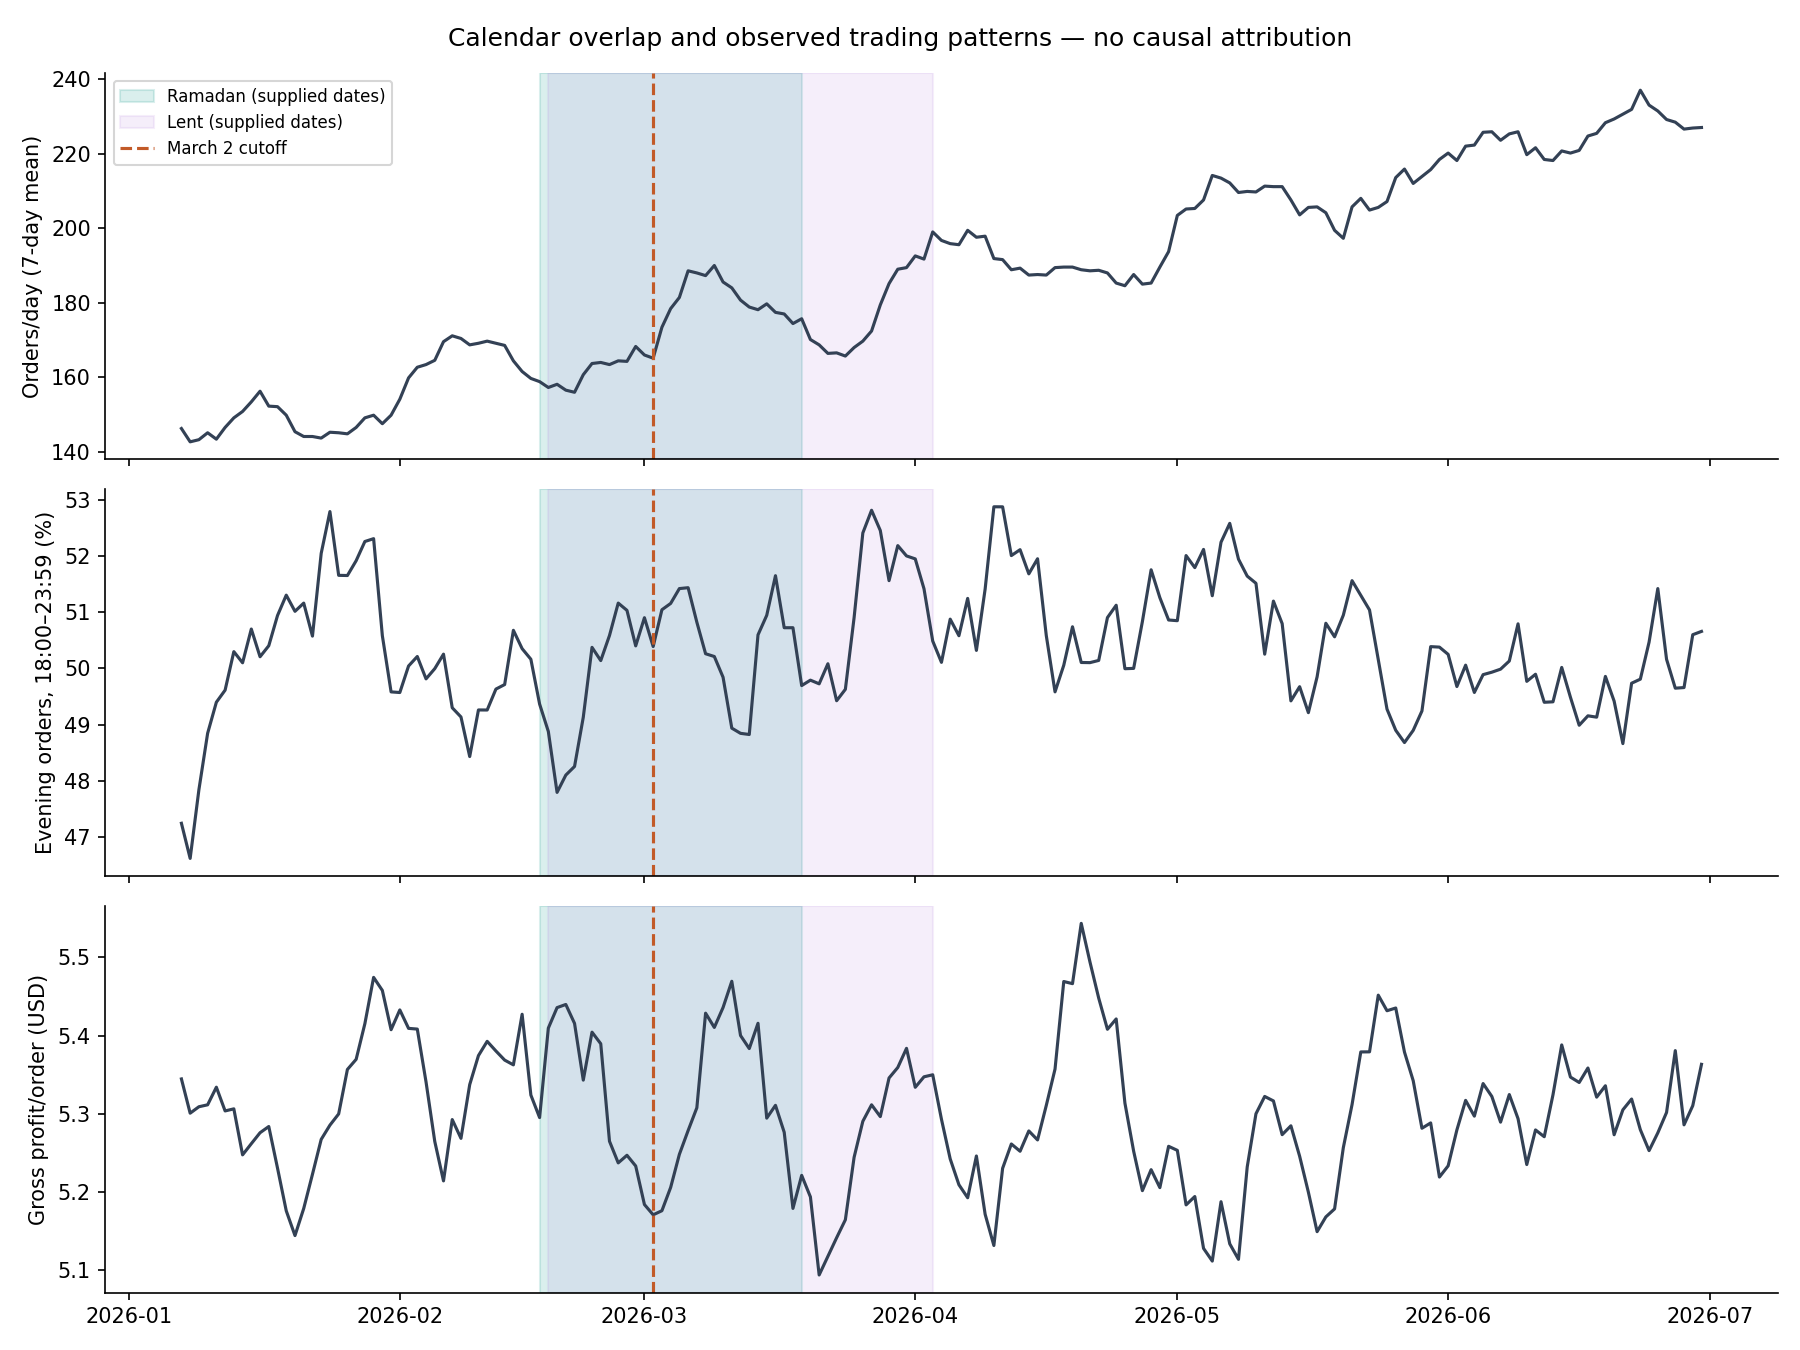

,branch,cutoff,days_each_side,before_orders,after_orders,order_change_pct
0,All branches,2026-01-29,28,4133,4577,10.742802
1,All branches,2026-02-05,28,4253,4682,10.086997
2,All branches,2026-02-12,28,4385,4782,9.053592
3,All branches,2026-02-19,28,4477,4902,9.492964
4,All branches,2026-02-26,28,4577,4934,7.799869
5,All branches,2026-03-02,28,4611,5030,9.086966
6,All branches,2026-03-05,28,4682,5033,7.496796
7,All branches,2026-03-12,28,4782,5128,7.235466
8,All branches,2026-03-19,28,4902,5220,6.487148
9,All branches,2026-03-26,28,4934,5365,8.735306


,branch,model,horizon,mae,absolute_error,actual_total,folds,wape
0,Garden,previous_weekday,14,8.047619,338.000000,2294.0,3,0.147341
1,Garden,previous_weekday,28,9.285714,260.000000,1534.0,1,0.169492
2,Garden,recent_weekday_average,14,6.785714,285.000000,2294.0,3,0.124237
3,Garden,recent_weekday_average,28,8.017857,224.500000,1534.0,1,0.146349
4,Garden,trend_weekday,14,6.255102,262.714286,2294.0,3,0.114522
5,Garden,trend_weekday,28,7.237245,202.642857,1534.0,1,0.132101
6,Harbour,previous_weekday,14,10.523810,442.000000,3298.0,3,0.134021
7,Harbour,previous_weekday,28,10.142857,284.000000,2194.0,1,0.129444
8,Harbour,recent_weekday_average,14,9.869048,414.500000,3298.0,3,0.125682
9,Harbour,recent_weekday_average,28,9.767857,273.500000,2194.0,1,0.124658


,branch,model,actual_orders,projected_orders,deviation_fraction
0,Garden,trend_weekday,1640,1676.763206,-0.021925
1,Harbour,recent_weekday_average,2419,2192.000000,0.103558
2,Uptown,trend_weekday,971,901.721311,0.076829


,branch,model,projected_orders,actual_orders,deviation_fraction
0,Garden,previous_weekday,1604.000000,1640,0.022444
1,Garden,recent_weekday_average,1560.000000,1640,0.051282
2,Garden,trend_weekday,1676.763206,1640,-0.021925
3,Harbour,previous_weekday,2160.000000,2419,0.119907
4,Harbour,recent_weekday_average,2192.000000,2419,0.103558
5,Harbour,trend_weekday,2296.440801,2419,0.053369
6,Uptown,previous_weekday,884.000000,971,0.098416
7,Uptown,recent_weekday_average,859.000000,971,0.130384
8,Uptown,trend_weekday,901.721311,971,0.076829


,branch,category,policy,mae,absolute_error,actual_units,wape
0,Garden,Bakery,previous_weekday,5.743802,695.00,2686,0.258749
1,Garden,Bakery,recent_4_weekdays,4.524793,547.50,2686,0.203835
2,Garden,Meals,previous_weekday,1.743802,211.00,375,0.562667
3,Garden,Meals,recent_4_weekdays,1.487603,180.00,375,0.480000
4,Harbour,Bakery,previous_weekday,7.520661,910.00,4221,0.215589
5,Harbour,Bakery,recent_4_weekdays,5.493802,664.75,4221,0.157486
6,Harbour,Meals,previous_weekday,2.900826,351.00,534,0.657303
7,Harbour,Meals,recent_4_weekdays,2.196281,265.75,534,0.497659
8,Uptown,Bakery,previous_weekday,3.884298,470.00,1512,0.310847
9,Uptown,Bakery,recent_4_weekdays,3.254132,393.75,1512,0.260417


In [3]:
display(Image(filename=str(OUTPUT / 'figures/calendar_timeline.png')))
display(pd.read_csv(OUTPUT / 'alternative_cutoff_comparisons.csv').query('branch == @chain'))
display(result['scores'])
display(pd.read_csv(OUTPUT / 'projection_summary.csv'))
display(pd.read_csv(OUTPUT / 'projection_model_sensitivity.csv'))
display(pd.read_csv(OUTPUT / 'preparation_backtest.csv'))

### Model evaluation: simple baselines and a separate later test

**Target:** recorded daily orders per branch. **Simple baseline:** repeat the last matching weekday available at the forecast origin. Also compare the prior-four-matching-weekdays average with linear trend plus weekday regression.

**Selection and training:** choose using three earlier 14-day validation folds (Jan 29–Feb 11, Feb 5–18, Feb 12–25), then refit on Jan 1–Mar 1. Those overlapping development folds, shown above, are not the final test. **Separate test:** Mar 2–29, 28 days per branch. Issue all predictions using history ending Mar 1; do not update with test sales or change choices after looking at errors. All three candidates face the same test dates.

**Read the scores:** MAE is average absolute error in orders per branch per day; WAPE is total absolute error divided by total actual orders. Lower is better. A positive MAE reduction means improvement over last matching weekday. The earlier-selected candidates reduce test MAE by 12.7% at Harbour, 17.9% at Garden, and 19.4% at Uptown. Complexity does not consistently help: Garden’s selected regression loses to the four-week average, and Harbour’s selected average loses to regression. Keep both losses visible.

These dates were already explored retrospectively, but are excluded from fitting and the coded selection rule. This is not a prospective trial, a causal no-war forecast, or proof of profit gains. Food preparation above forecasts units one day ahead using prior sales, so its errors answer a different operating question. The generated reports/forecast_evaluation.md records the split and full comparison.

,branch,candidate,selected_on_validation,train_start,train_end,test_start,test_end,test_days,mae,wape,bias,mae_reduction_vs_baseline_pct
0,Garden,Last matching weekday (baseline),False,2026-01-01,2026-03-01,2026-03-02,2026-03-29,28,8.214286,0.140244,-1.285714,0.000000
1,Garden,Prior four matching weekdays,False,2026-01-01,2026-03-01,2026-03-02,2026-03-29,28,6.035714,0.103049,-2.857143,26.521739
2,Garden,Linear trend + weekday,True,2026-01-01,2026-03-01,2026-03-02,2026-03-29,28,6.741998,0.115107,1.312972,17.923497
3,Harbour,Last matching weekday (baseline),False,2026-01-01,2026-03-01,2026-03-02,2026-03-29,28,12.392857,0.143448,-9.250000,0.000000
4,Harbour,Prior four matching weekdays,True,2026-01-01,2026-03-01,2026-03-02,2026-03-29,28,10.821429,0.125258,-8.107143,12.680115
5,Harbour,Linear trend + weekday,False,2026-01-01,2026-03-01,2026-03-02,2026-03-29,28,9.563752,0.110701,-4.377114,22.828512
6,Uptown,Last matching weekday (baseline),False,2026-01-01,2026-03-01,2026-03-02,2026-03-29,28,5.678571,0.163749,-3.107143,0.000000
7,Uptown,Prior four matching weekdays,False,2026-01-01,2026-03-01,2026-03-02,2026-03-29,28,5.160714,0.148816,-4.000000,9.119497
8,Uptown,Linear trend + weekday,True,2026-01-01,2026-03-01,2026-03-02,2026-03-29,28,4.577153,0.131988,-2.474239,19.396043


Dark outlines in the figure mark choices made using earlier validation, not choices made from test results.


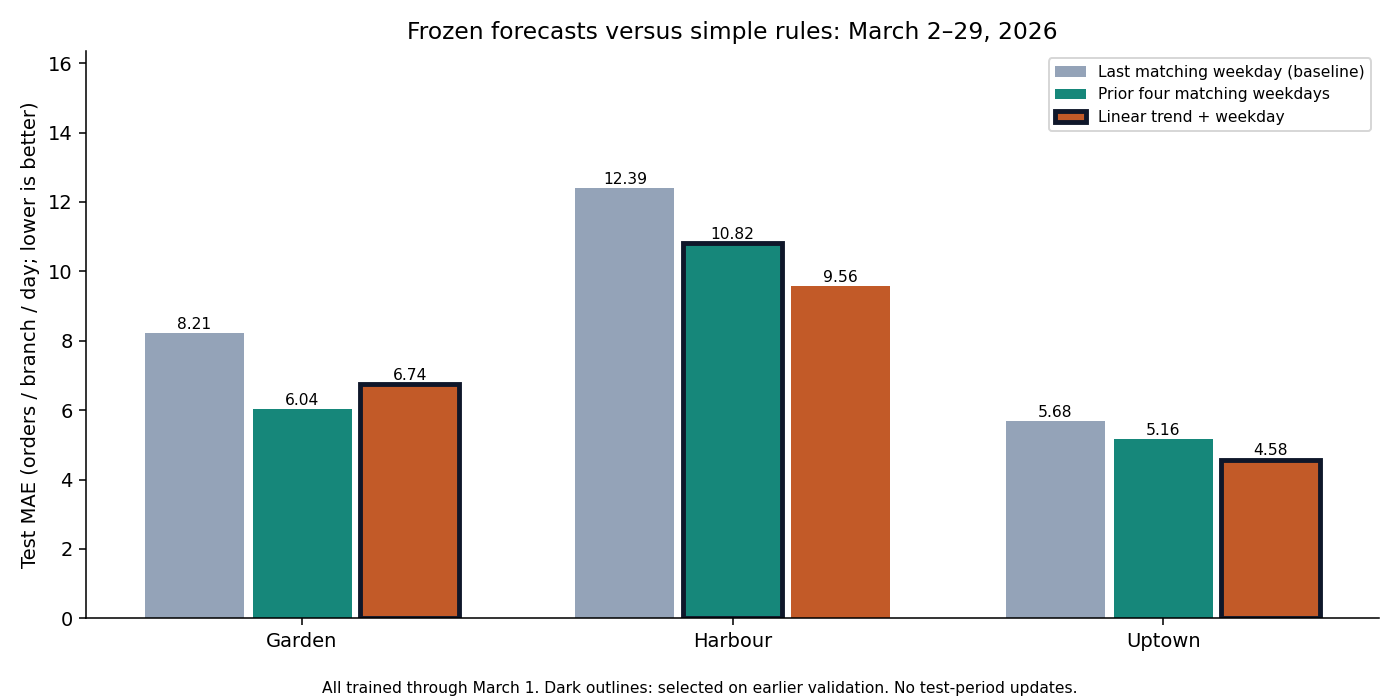

In [4]:
test_scores = result['holdout_scores'].copy()
test_scores['candidate'] = test_scores.model.map({
    'previous_weekday': 'Last matching weekday (baseline)',
    'recent_weekday_average': 'Prior four matching weekdays',
    'trend_weekday': 'Linear trend + weekday',
})
display(test_scores[['branch','candidate','selected_on_validation','train_start','train_end','test_start','test_end','test_days','mae','wape','bias','mae_reduction_vs_baseline_pct']])
print('Dark outlines in the figure mark choices made using earlier validation, not choices made from test results.')
display(Image(filename=str(OUTPUT / 'figures/forecast_holdout.png')))

## 3. Promotion comparison and uncertainty

**Conclusion 2: The observed promotion results do not establish that the discounts paid for themselves.**

Harbour has two recorded 15%-off Cold Coffee/Desserts windows, March 12–19 and May 12–19. The observational promotion comparison adjusts for common movements if the branches would otherwise have followed comparable relative trends. It does not establish the counterfactual without promotion. First-observed buyer counts cannot identify incremental customer acquisition.

The script below is included in this notebook for standalone Colab use. Its historical CSV filename, promotion_natural_experiment.csv, is retained for compatibility; the interpretation is observational. The approximately 29% same-mix break-even benchmark is an accounting comparison, not a unit-only expansion rule.

Break-even unit lift for 15% off: +29.3%
2026-03-12: Harbour promoted units/day 30.1 -> 30.1; relative to other branches +10.7%
2026-05-12: Harbour promoted units/day 37.6 -> 37.6; relative to other branches -4.4%
Overlapping non-promotion comparisons: n=60, empirical central 95% range -21.1% to +16.2%. Descriptive variation only; not a confidence interval or power test.


,promo_start,promo_end,metric,harbour_pre_per_day,harbour_during_per_day,harbour_post_per_day,others_pre_per_day,others_during_per_day,others_post_per_day,harbour_vs_others_change_pct,harbour_during_total,break_even_unit_lift_pct
0,2026-03-12,2026-03-19,promo_cat_units,30.142857,30.12500,32.714286,35.642857,32.6250,39.785714,10.719111,241.00,29.340165
1,2026-03-12,2026-03-19,other_units,108.928571,103.50000,102.000000,115.142857,112.2500,117.000000,1.445318,828.00,29.340165
2,2026-03-12,2026-03-19,orders,86.500000,84.62500,85.071429,94.714286,89.8750,95.642857,4.461442,677.00,29.340165
3,2026-03-12,2026-03-19,promo_cat_gross_profit,115.367143,89.87250,124.898571,103.722143,93.2475,113.052857,-13.055152,718.98,29.340165
4,2026-03-12,2026-03-19,gross_profit,518.389286,476.75000,505.978571,445.742143,422.8525,457.483571,-0.619687,3814.00,29.340165
5,2026-03-12,2026-03-19,promo_cat_discount_usd,0.852857,26.23375,0.944286,1.039286,1.0850,1.520000,3253.804883,209.87,29.340165
6,2026-05-12,2026-05-19,promo_cat_units,37.642857,37.62500,39.285714,36.571429,38.5000,38.714286,-4.379113,301.00,29.340165
7,2026-05-12,2026-05-19,other_units,126.000000,129.25000,129.500000,129.214286,138.3750,138.714286,-2.126371,1034.00,29.340165
8,2026-05-12,2026-05-19,orders,102.714286,102.75000,104.857143,106.714286,112.3750,111.000000,-4.114835,822.00,29.340165
9,2026-05-12,2026-05-19,promo_cat_gross_profit,144.242143,111.34250,150.544286,105.357857,110.8475,110.945714,-26.304451,890.74,29.340165


,window_start,harbour_vs_others_change_pct
0,2026-01-15,-17.983437
1,2026-01-16,-24.476496
2,2026-01-17,-23.949072
3,2026-01-18,-12.750195
4,2026-01-19,-7.148470
5,2026-01-20,-8.042541
6,2026-01-21,-7.334671
7,2026-01-22,-8.665355
8,2026-01-23,13.516889
9,2026-01-24,21.825870


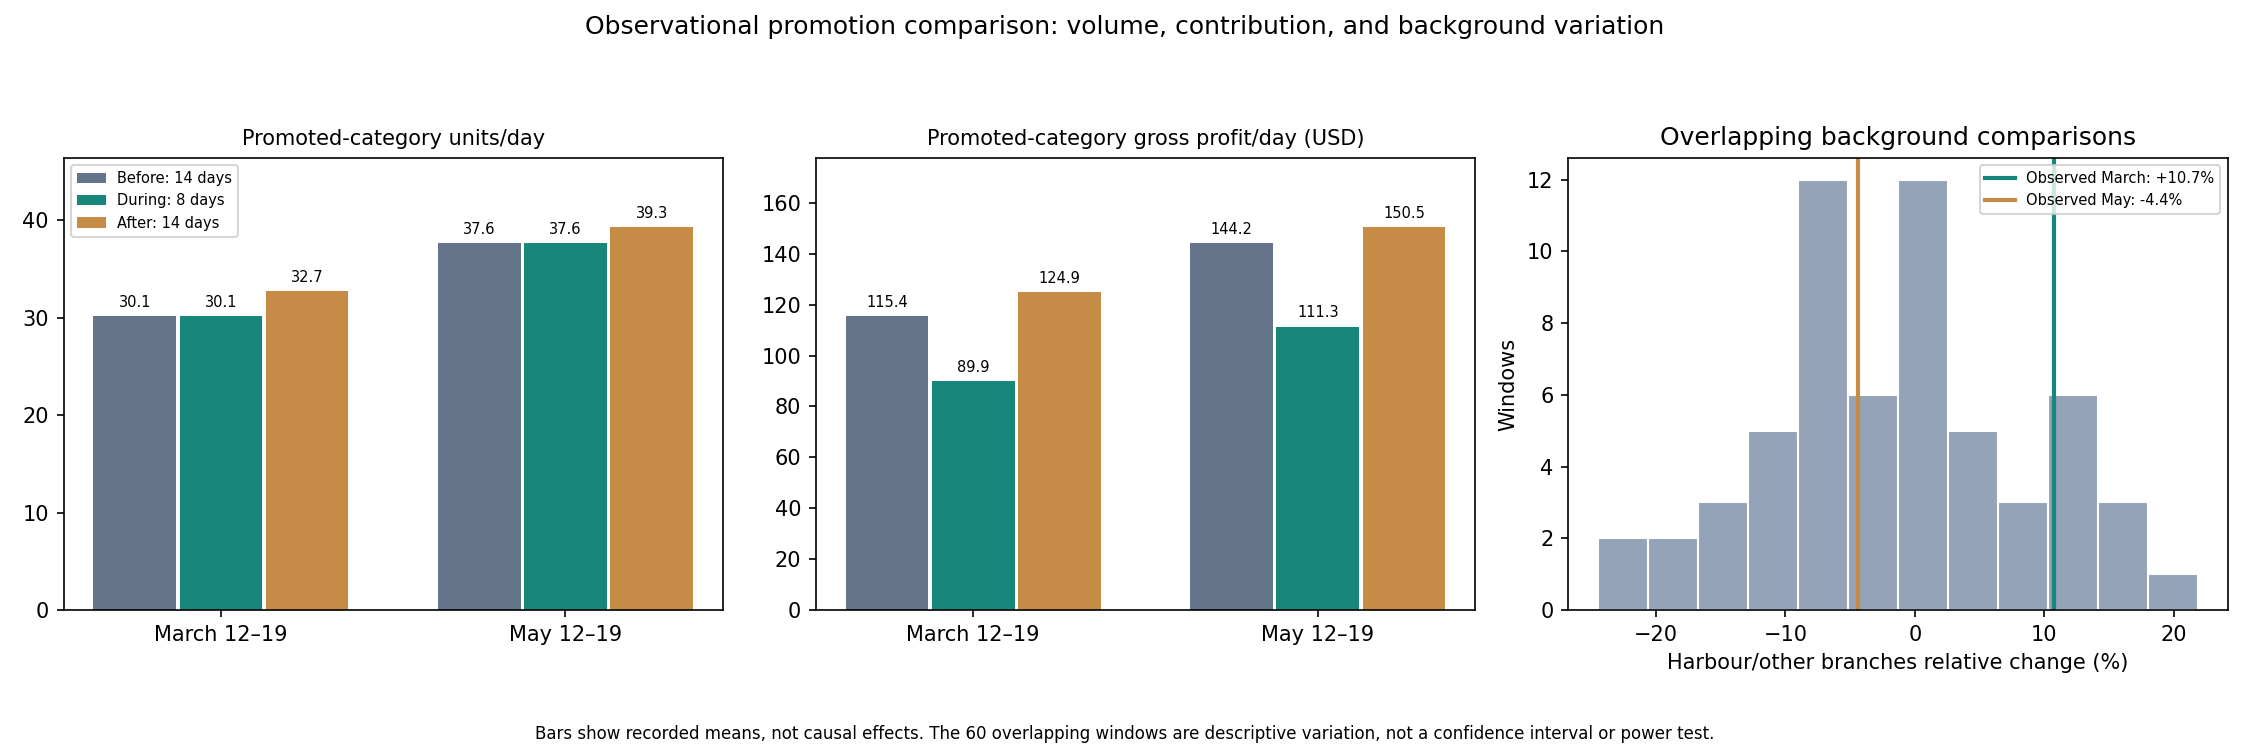

In [5]:
import subprocess

subprocess.run(
    [
        sys.executable,
        str(PROJECT / "scripts/promotion_test.py"),
        "--data", str(DATA),
    ],
    check=True,
)

display(pd.read_csv(OUTPUT / "promotion_natural_experiment.csv"))
display(pd.read_csv(OUTPUT / "promotion_placebo.csv"))
display(Image(filename=str(OUTPUT / "figures/promotion_comparison.png")))

**Uncertainty:** the 60 overlapping non-promotion windows produced relative changes with a central 95% range of approximately −21% to +16%. The observed promotion comparisons, +10.7% and −4.4%, lie within this background variation. This does not establish zero effect or rule out a break-even effect: negative background variation can mask positive promotion effects. These overlapping windows are descriptive sensitivity checks, not independent experiments or a calibrated power analysis.

**Measured:** the two promotion windows recorded $471.55 in discounts relative to listed prices. This is not a measured causal profit loss: the quantities customers would have purchased without the promotion are unknown. **Conditional scenario:** holding quantities and product mix unchanged, charging full listed prices would have increased recorded gross profit by $471.55. Ordinary discounts, changes in demand, substitution, and later purchases could reduce or reverse that difference. We recommend a randomized holdout before repeating the promotion.

In [6]:
promotion = pd.read_csv(OUTPUT / 'promotion_natural_experiment.csv')
background = pd.read_csv(OUTPUT / 'promotion_placebo.csv')
discounts = promotion.query("metric == 'promo_cat_discount_usd'")
display(discounts[['promo_start','promo_end','harbour_during_total']].rename(columns={'harbour_during_total':'discount_relative_to_listed_prices_usd'}))
print(f"Observed discount relative to listed prices: ${discounts.harbour_during_total.sum():,.2f}")
print(f"Same-mix unit break-even benchmark: {promotion.break_even_unit_lift_pct.iloc[0]:.1f}%")
display(background.harbour_vs_others_change_pct.quantile([.025,.975]).rename('empirical_relative_change_pct'))

,promo_start,promo_end,discount_relative_to_listed_prices_usd
5,2026-03-12,2026-03-19,209.87
11,2026-05-12,2026-05-19,261.68


Observed discount relative to listed prices: $471.55
Same-mix unit break-even benchmark: 29.3%


0.025   -21.115395
0.975    16.227463
Name: empirical_relative_change_pct, dtype: float64

## 4. Customer continuity and timing

**Conclusion 3: Check chain-wide activity and test inactivity thresholds before targeting customers.**

Among the 1,978 identified accounts active in the baseline window, 1,692 were observed again within 56 days and 286 were not observed. These are observed-account return measures, not estimates of permanent customer loss.

Among baseline accounts not observed again at their original branch during the next 28 days, the share observed elsewhere was 49.2% for Garden, 38.9% for Harbour, and 50.7% for Uptown. Branch cohorts overlap and must not be summed as unique customers. Customer findings cover identified accounts only; 36.5% of orders lack IDs. Cross-branch results assume globally consistent IDs.

Of 774 baseline accounts unobserved during the first 28-day follow-up, 488 appeared during days 29–56. Their returns may already have been influenced by existing activity or interventions. This count does not measure avoidable incentives or prove that earlier contact would be ineffective.

The historical cohort is based on calendar windows, not an exact individual last-purchase-indexed eligibility rule. First-observed IDs are not verified new customers; previously observed and observed return are the appropriate terms.

,event,cutoff,days_each_side,branch,period,total_orders,identified_orders,id_coverage,active_identified_customers,orders_per_active_customer,distinct_customer_days,days_per_active_customer,repeat_day_customer_share,identified_gross_profit,identified_gross_profit_per_order
8,March 2 / war context,2026-03-02,28,All branches,Before,4611,2963,0.642594,1978,1.497978,2898,1.465116,0.365015,15634.95,5.276730
9,March 2 / war context,2026-03-02,28,All branches,After,5030,3188,0.633797,2104,1.515209,3123,1.484316,0.370247,16625.47,5.215016


,event,cutoff,days_each_side,branch,identified_order_change,breadth_component_orders,frequency_component_orders,breadth_share_of_change,frequency_share_of_change
4,March 2 / war context,2026-03-02,28,All branches,225,189.830773,35.169227,0.843692,0.156308


,event,cutoff,days_each_side,branch,segment,customers,before_orders,after_orders,before_gross_profit,after_gross_profit,after_only_seen_earlier
12,March 2 / war context,2026-03-02,28,All branches,Observed in both windows,1204,1805,1837,9546.02,9484.44,NaN
13,March 2 / war context,2026-03-02,28,All branches,Observed only in before window,774,1158,0,6088.93,0.00,NaN
14,March 2 / war context,2026-03-02,28,All branches,Observed only in after window,900,0,1351,0.00,7141.03,508.0


,event,cutoff,days_each_side,calibration_start,calibration_end,minimum_calibration_visit_days,period,cohort_customers,active_cohort_customers,orders,distinct_customer_days,orders_per_cohort_member,gross_profit,gross_profit_per_cohort_member
6,March 2 / war context,2026-03-02,28,2026-01-05,2026-02-01,1,Before,1845,1047,1590,1553,0.861789,8369.38,4.536249
7,March 2 / war context,2026-03-02,28,2026-01-05,2026-02-01,1,After,1845,1108,1696,1662,0.919241,8806.19,4.773003
8,March 2 / war context,2026-03-02,28,2026-01-05,2026-02-01,2,Before,584,340,504,488,0.863014,2662.27,4.558682
9,March 2 / war context,2026-03-02,28,2026-01-05,2026-02-01,2,After,584,341,513,504,0.878425,2656.57,4.548921
10,March 2 / war context,2026-03-02,28,2026-01-05,2026-02-01,3,Before,135,81,114,111,0.844444,579.20,4.290370
11,March 2 / war context,2026-03-02,28,2026-01-05,2026-02-01,3,After,135,77,114,113,0.844444,602.12,4.460148


,event,cutoff,days_each_side,branch,before_customers,observed_same_branch_after,observed_other_branches_only_after,not_observed_chain_after,apparent_branch_absent,share_of_apparent_branch_absence_seen_elsewhere,elsewhere_only_recorded_gross_profit
3,March 2 / war context,2026-03-02,28,Garden,864,242,306,316,622,0.491961,2353.34
4,March 2 / war context,2026-03-02,28,Harbour,1166,405,296,465,761,0.388962,1675.59
5,March 2 / war context,2026-03-02,28,Uptown,507,81,216,210,426,0.507042,1605.55


,cutoff,baseline_days,followup_days,followup_end,baseline_customers,observed_return_customers,observed_return_rate,not_observed_customers,initially_absent_customers,initially_absent_seen_by_horizon,later_return_share_of_initial_absence
14,2026-03-02,28,28,2026-03-29,1978,1204,0.608696,774,774,0,0.000000
15,2026-03-02,28,56,2026-04-26,1978,1692,0.855410,286,774,488,0.630491


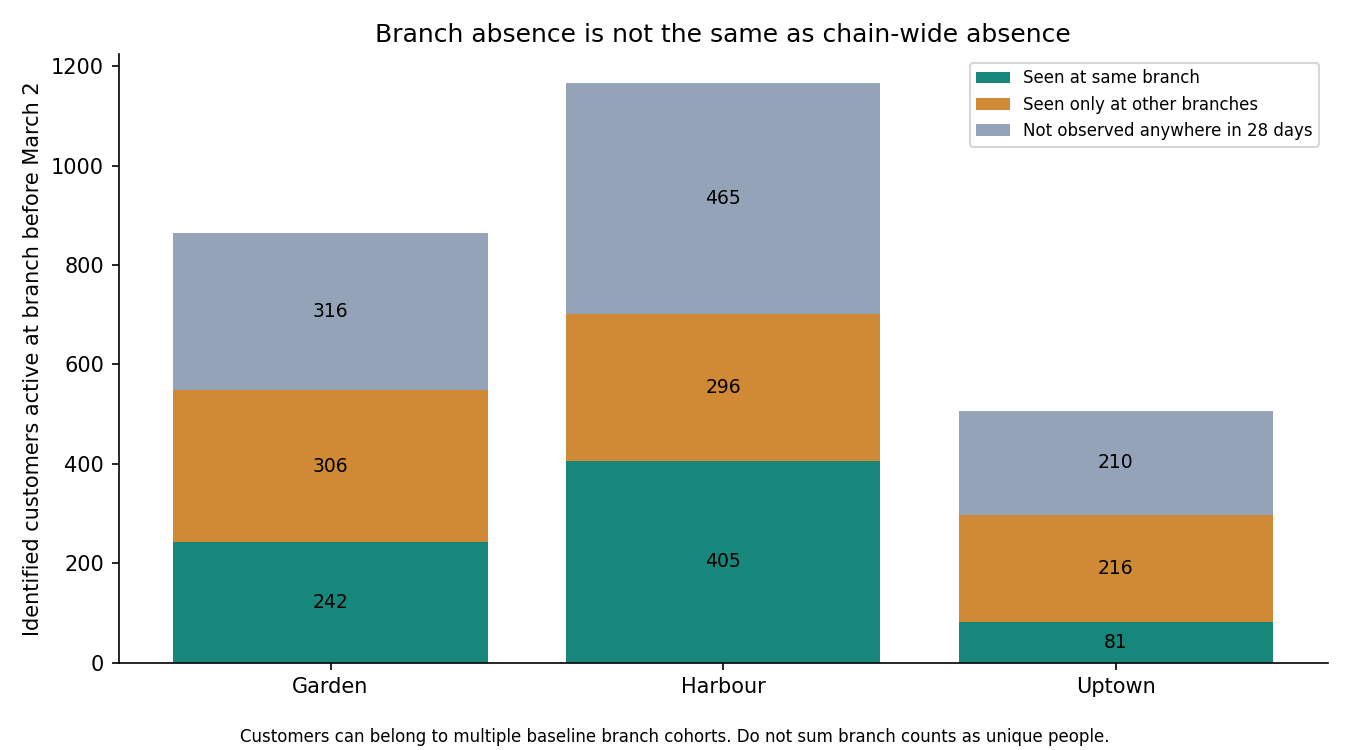

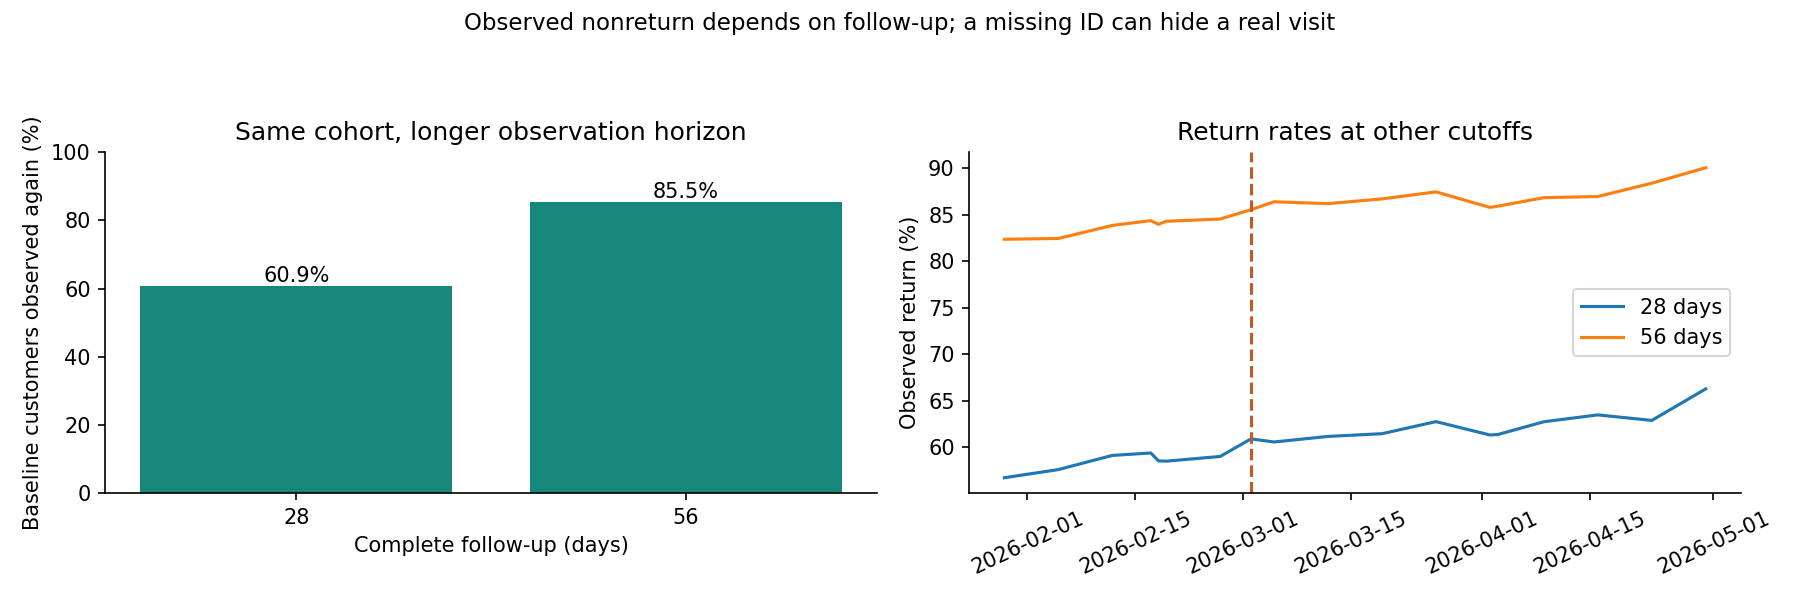

In [7]:
display(cust['summary'].query('event == @event_name and days_each_side == @width and branch == @chain'))
display(cust['decomposition'].query('event == @event_name and days_each_side == @width and branch == @chain'))
display(cust['flows'].query('event == @event_name and days_each_side == @width and branch == @chain'))
display(cust['cohorts'].query('event == @event_name and days_each_side == @width'))
display(cust['continuity'].query('cutoff == @cutoff and days_each_side == @width'))
display(cust['followup'].query('cutoff == @cutoff'))
display(Image(filename=str(OUTPUT / 'figures/customer_branch_continuity.png')))
display(Image(filename=str(OUTPUT / 'figures/customer_followup.png')))

## 5. Conditional economics and pilot decisions

**Preparation:** evaluate a recent-demand rule using waste, availability, wait-time, and operating-cost records before translating forecast improvements into profit.

**Promotion:** expand only if the randomized comparison shows a pre-agreed worthwhile improvement in total branch gross contribution after discounts and incremental operating costs. Report promoted-category units and the approximately 29% same-mix break-even benchmark as supporting measures. Include gains/losses elsewhere in the basket.

**Test intervention timing:** compare contacting accounts after 28 days without an identified chain-wide purchase with contacting them after 56 days if they remain inactive. Historical returns do not establish which timing produces higher incremental contribution. Eligibility begins 28 days after each account’s last recorded chain-wide purchase. Randomize eligible accounts to contact immediately or wait another 28 days and contact only if still inactive. Evaluate both groups for 56 days from randomization, retaining every assigned account in the denominator.

The 488 later observed accounts are not an avoided-incentive estimate. A scenario in which 1% of baseline identified accounts make one genuinely additional order is hypothetical, before intervention and other incremental costs. No campaign or pilot has been run.

In [8]:
# Keep only the additional-order scenarios; no historical-return count is priced as avoided incentives.
display(cust['value_scenarios'].query('pattern == 1'))
display(pd.read_csv(OUTPUT / 'duplicate_sensitivity.csv'))

,pattern,scenario,conditional_contribution_usd,assumptions
0,1,1% of baseline identified customers make one g...,103.153010,Observed mean identified-order gross profit; n...
1,1,2% of baseline identified customers make one g...,206.306020,Observed mean identified-order gross profit; n...
2,1,5% of baseline identified customers make one g...,515.765051,Observed mean identified-order gross profit; n...


,branch,orders,units,revenue,gross_profit,gross_margin,gross_profit_per_order,duplicate_policy
0,Garden,11163,17833,99748.55,46794.49,0.469125,4.191928,retain
1,Harbour,16334,26093,150483.58,97753.94,0.649599,5.984691,retain
2,Uptown,6390,10161,55693.01,34882.06,0.626327,5.458851,retain
3,Garden,11163,17795,99530.55,46696.16,0.469164,4.183119,exact_deduplicate
4,Harbour,16334,26025,150099.05,97503.46,0.649594,5.969356,exact_deduplicate
5,Uptown,6390,10135,55554.11,34794.66,0.626320,5.445174,exact_deduplicate


## 6. Supporting food-offer and branch-cost analyses

Earlier food offers, product comparisons, and branch-cost investigations remain supporting material. They do not replace the three conclusions above. Same-product cost gaps are accounting/procurement hypotheses, not attainable savings; historical co-purchases do not estimate incremental response to a suggestion. Calendar regressions are retrospective and model-dependent. See the original supplied notebooks in notebooks/reference and the supporting reports for details.

,branch,category,product,food_units,weighted_list_price,weighted_unit_cost,observed_gross_profit_per_unit,normal_price_contribution,max_discount_for_2_usd_contribution,two_usd_contribution_feasible,drink_orders,historical_eligible_orders,existing_pair_orders,existing_pair_rate
1,Garden,Bakery,Banana Bread,62,4.45,2.25,2.141935,2.20,0.20,True,964,695,27,0.028008
0,Garden,Bakery,Almond Croissant,48,4.85,2.73,2.099583,2.12,0.12,True,964,695,20,0.020747
2,Garden,Bakery,Blueberry Muffin,54,3.95,1.87,2.080000,2.08,0.08,True,964,695,19,0.019710
3,Garden,Bakery,Butter Croissant,99,3.65,1.63,2.005152,2.02,0.02,True,964,695,42,0.043568
5,Garden,Bakery,Chocolate Croissant,76,4.25,2.26,1.967368,1.99,0.00,False,964,695,40,0.041494
6,Garden,Bakery,Cinnamon Roll,64,5.15,3.20,1.918125,1.95,0.00,False,964,695,26,0.026971
4,Garden,Bakery,Chocolate Cookie,86,3.15,1.30,1.835581,1.85,0.00,False,964,695,40,0.041494
7,Garden,Bakery,Pistachio Cookie,62,3.45,1.69,1.727097,1.76,0.00,False,964,695,25,0.025934
9,Garden,Meals,Quinoa Bowl,30,11.65,7.04,4.494000,4.61,2.61,True,964,695,11,0.011411
8,Garden,Meals,Chicken Salad Bowl,30,12.45,8.08,4.328333,4.37,2.37,True,964,695,15,0.015560


,branch,drink_orders,bakery_attachment,meal_attachment,historical_eligible_orders
0,Garden,964,0.245851,0.037344,695
1,Harbour,1448,0.225138,0.017265,1099
2,Uptown,577,0.216638,0.020797,440


price_ratio_to_reference                     cost_ratio_to_reference  \
                             min    median       max                     min   
branch                                                                         
Garden                  0.951220  0.952576  0.953237                1.426087   
Harbour                 1.000000  1.000000  1.000000                1.000000   
Uptown                  0.912195  0.914116  0.915842                0.952381   

                             
           median       max  
branch                       
Garden   1.430233  1.438596  
Harbour  1.000000  1.000000  
Uptown   0.959641  0.965116

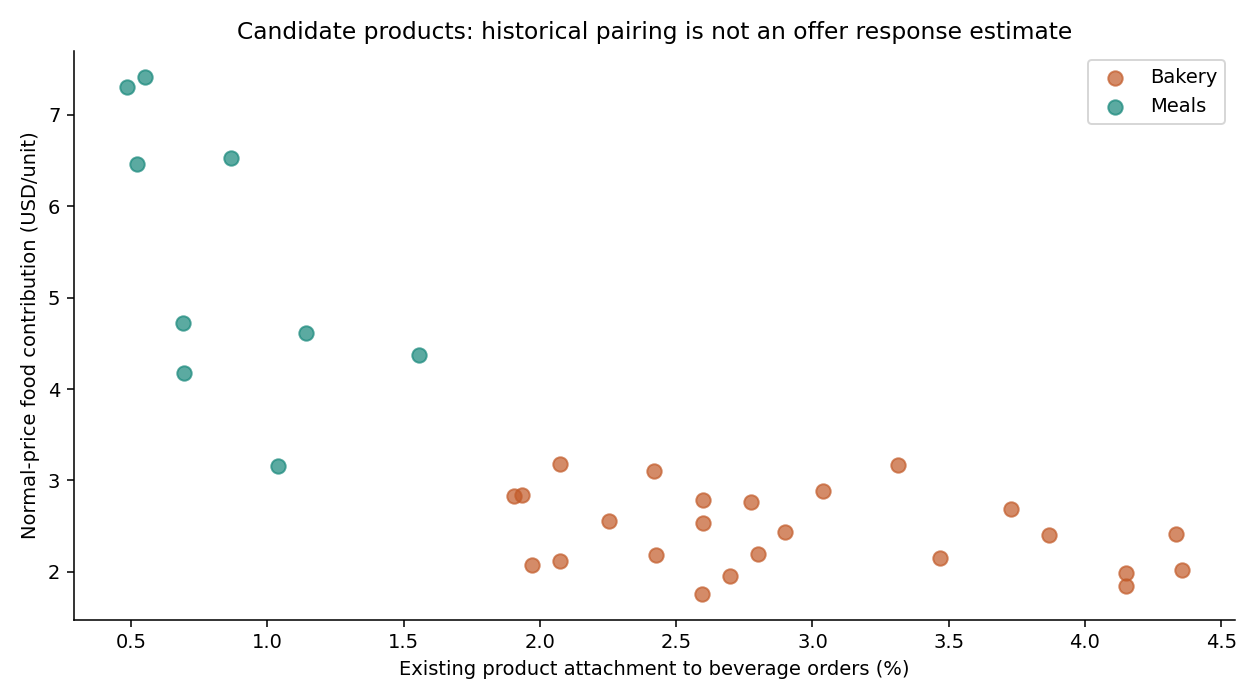

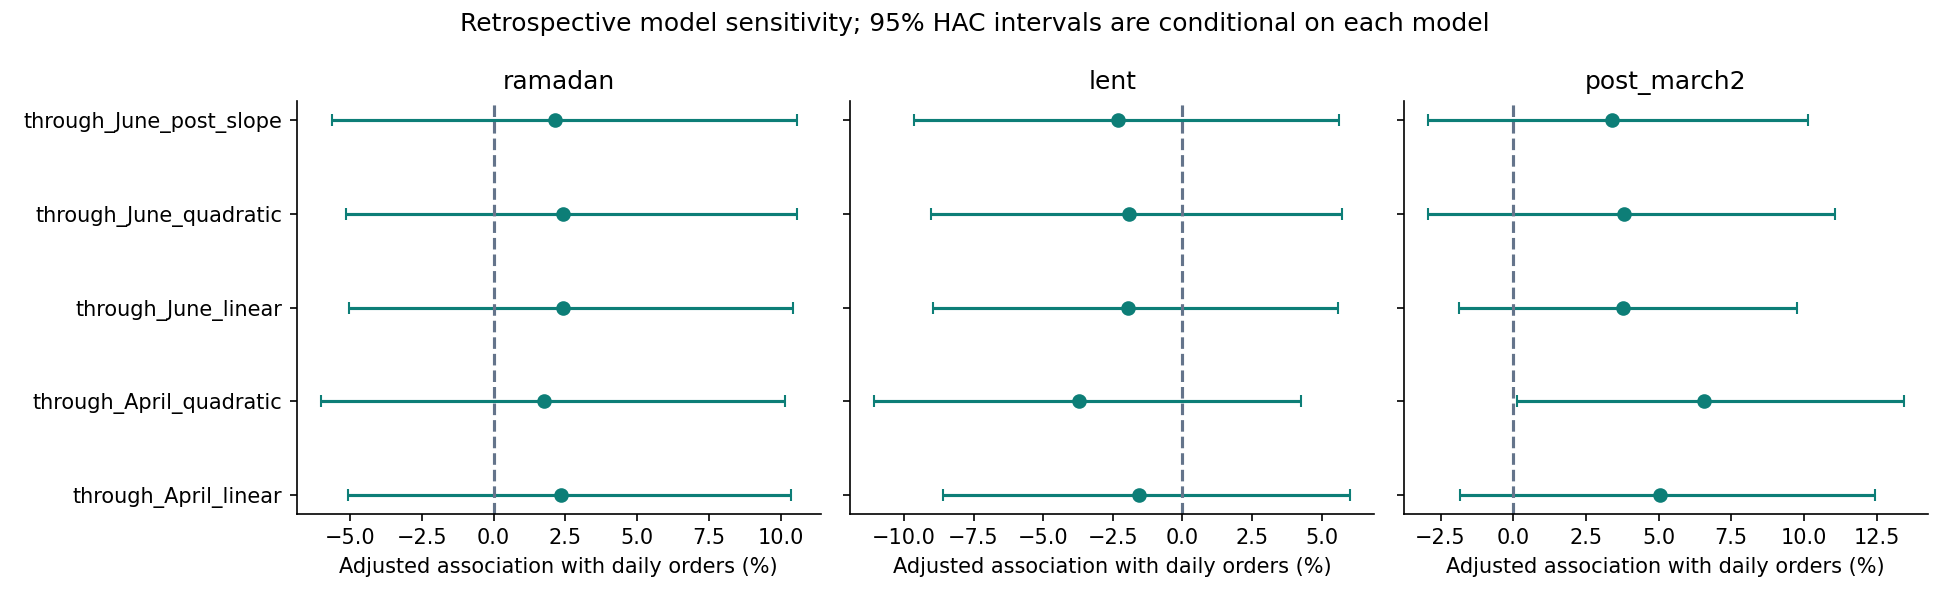

In [9]:
display(result['opportunities'])
display(pd.read_csv(OUTPUT / 'basket_summary.csv'))
display(diag['cost'].groupby('branch')[['price_ratio_to_reference','cost_ratio_to_reference']].agg(['min','median','max']))
display(Image(filename=str(OUTPUT / 'figures/offer_tradeoff.png')))
display(Image(filename=str(OUTPUT / 'figures/calendar_model_sensitivity.png')))